### init

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["JAX_PLATFORMS"] = "cpu"

import wandb
from tqdm import tqdm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%load_ext autoreload
%autoreload 2

In [2]:
def get_figsize(columnwidth, wf=0.5, hf=(5.**0.5-1.0)/2.0, ):
    """Parameters:
    - wf [float]:  width fraction in columnwidth units
    - hf [float]:  height fraction in columnwidth units.
                    Set by default to golden ratio.
    - columnwidth [float]: width of the column in latex. Get this from LaTeX 
                            using \showthe\columnwidth
    Returns:  [fig_width,fig_height]: that should be given to matplotlib
    """
    fig_width_pt = columnwidth*wf
    inches_per_pt = 1.0/72.27               # Convert pt to inch
    fig_width = fig_width_pt*inches_per_pt  # width in inches
    fig_height = fig_width*hf      # height in inches
    return [fig_width, fig_height]


# fig_width_pt = 234.8  # Get this from LaTeX using \showthe\columnwidth
fig_width_pt = 397.48499  # Get this from LaTeX using \showthe\columnwidth
inches_per_pt = 1.0/72.27               # Convert pt to inches
golden_mean = (np.sqrt(5)-1.0)/2.0         # Aesthetic ratio
fig_width = fig_width_pt*inches_per_pt  # width in inches
fig_height = fig_width*golden_mean       # height in inches
figsize = [fig_width, fig_height]
print("Figure size=", figsize)
tex_fonts = {
    # Use LaTeX to write all text
    "text.usetex": True,
    # "text.latex.preamble": r'\usepackage{amsfonts}',
    "font.family": "Nimbus Sans",
    # Use 10pt font in plots, to match 10pt font in document
    "axes.labelsize": 10,
    "font.size": 10,
    # Make the legend/label fonts a little smaller
    "legend.fontsize": 9,
    "legend.title_fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize": figsize
}
plt.rcParams.update(tex_fonts)

Figure size= [5.499999861629998, 3.399186852607058]


### Curve length with adding delta w

In [4]:
api = wandb.Api()
results = []


for s in ["4lzudwro",]: # 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        space = len(run.config['curve_params']['cp_fix'])
        if space == 1:
            acc=run.summary.get(f"cp_fixed_0_post_pred_test_mean_acc", 0)
            ece=run.summary.get(f"cp_fixed_0_post_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"cp_fixed_0_post_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        else:
            if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
                acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
                ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
                nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
                test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
                test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
                std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
                mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
            else:
                acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
                ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
                nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

                test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
                test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
                std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
                mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            DegFreedom=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Model=f"Flat_MLE",
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)

df = pd.DataFrame(results)
# df['CurveSpace'] = df['CurveSpace'].apply(lambda x: 'MLE' if x == 0 else f'Curve_{x}')
df.head()

4lzudwro:   0%|          | 0/72 [00:00<?, ?it/s, whole-sweep-53]      

4lzudwro: 100%|██████████| 72/72 [00:00<00:00, 276.02it/s, lemon-sweep-25]        


Skipping lunar-sweep-18 because it is not finished
Skipping feasible-sweep-17 because it is not finished
Skipping silvery-sweep-16 because it is not finished
Skipping atomic-sweep-15 because it is not finished
Skipping exalted-sweep-14 because it is not finished
Skipping fluent-sweep-13 because it is not finished
Skipping dry-sweep-6 because it is not finished
Skipping breezy-sweep-5 because it is not finished
Skipping silver-sweep-4 because it is not finished
Skipping swift-sweep-3 because it is not finished
Skipping cool-sweep-2 because it is not finished
Skipping effortless-sweep-1 because it is not finished


,Id,DegFreedom,CpFix,Model,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,...,Tsample,LoraRho,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,k4olxcic,1,[1],Flat_MLE,0,2,0.01,obqa,ppd,minibatch,...,per_leaf,0.0,0.0,0.906,0.036953,0.279377,-inf,-inf,-inf,-inf
1,yriutusa,1,[1],Flat_MLE,0,1,0.01,obqa,ppd,minibatch,...,per_leaf,0.0,0.0,0.904,0.019531,0.255603,-inf,-inf,-inf,-inf
2,io8c8o82,1,[1],Flat_MLE,0,2,0.01,obqa,ppd,minibatch,...,per_leaf,0.1,0.0,0.916,0.031477,0.215207,-inf,-inf,-inf,-inf
3,nr37slbq,1,[1],Flat_MLE,0,1,0.01,obqa,ppd,minibatch,...,per_leaf,0.1,0.0,0.908,0.038449,0.237949,-inf,-inf,-inf,-inf
4,yxlcgs33,1,[1],Flat_MLE,0,2,0.01,obqa,ppd,minibatch,...,per_leaf,0.5,0.0,0.904,0.027926,0.252398,-inf,-inf,-inf,-inf


In [5]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,DegFreedom,CpFix,Model,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,Tsample,LoraRho,,,,,,,,


In [14]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
DegFreedom [1 3]
CpFix ['[1]' '[0, 0, 0]' '[1, 0, 1]']
Model ['Flat_MLE']
Jitter [0]
Seed [2 1]
WeightDecay [0.01]
Dataset ['obqa' 'winogrande_m']
Metric ['ppd']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [0]
NumSteps [5000]
LoraMode ['A(t)B(t)' 'Asd(t)B']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['per_leaf']
LoraRho [0.  0.1 0.5]

Experiment differs in ['DegFreedom', 'CpFix', 'Dataset', 'LoraMode', 'LoraRho'] configs


array(['obqa', 'winogrande_m'], dtype=object)

#### curve length

In [15]:
df_clean[variable_idx + ['bezierLength']].groupby(variable_idx).describe()

bezierLength             \
                                                          count       mean   
DegFreedom CpFix     Dataset      LoraMode LoraRho                           
1          [1]       obqa         A(t)B(t) 0.0              2.0   0.000000   
                                           0.1              2.0   0.000000   
                                           0.5              2.0   0.000000   
                                  Asd(t)B  0.0              2.0   0.000000   
                                           0.1              2.0   0.000000   
                                           0.5              2.0   0.000000   
                     winogrande_m A(t)B(t) 0.0              2.0   0.000000   
                                           0.1              2.0   0.000000   
                                           0.5              2.0   0.000000   
                                  Asd(t)B  0.0              2.0   0.000000   
                                           0.1              2.0   0.000000   
                                           0.5              2.0   0.000000   
3          [0, 0, 0] obqa         A(t)B(t) 0.0              2.0  25.395664   
                                           0.1              2.0  25.333452   
                                           0.5              2.0  25.766871   
                                  Asd(t)B  0.0              2.0  41.538078   
                                           0.1              2.0  41.545992   
                                           0.5              2.0  41.534657   
                     winogrande_m A(t)B(t) 0.0              2.0  24.910491   
                                           0.1              2.0  24.898174   
                                           0.5              2.0  25.623293   
                                  Asd(t)B  0.0              2.0  41.610138   
                                           0.1              2.0  41.621960   
                                           0.5              2.0  41.551245   
           [1, 0, 1] obqa         A(t)B(t) 0.0              2.0  26.690658   
                                           0.1              2.0  26.588102   
                                           0.5              2.0  28.143085   
                     winogrande_m A(t)B(t) 0.0              2.0  25.707582   
                                           0.1              2.0  25.973811   
                                           0.5              2.0  28.455189   

                                                                         \
                                                         std        min   
DegFreedom CpFix     Dataset      LoraMode LoraRho                        
1          [1]       obqa         A(t)B(t) 0.0      0.000000   0.000000   
                                           0.1      0.000000   0.000000   
                                           0.5      0.000000   0.000000   
                                  Asd(t)B  0.0      0.000000   0.000000   
                                           0.1      0.000000   0.000000   
                                           0.5      0.000000   0.000000   
                     winogrande_m A(t)B(t) 0.0      0.000000   0.000000   
                                           0.1      0.000000   0.000000   
                                           0.5      0.000000   0.000000   
                                  Asd(t)B  0.0      0.000000   0.000000   
                                           0.1      0.000000   0.000000   
                                           0.5      0.000000   0.000000   
3          [0, 0, 0] obqa         A(t)B(t) 0.0      0.252590  25.217056   
                                           0.1      0.203942  25.189243   
                                           0.5      0.057558  25.726171   
                                  Asd(t)B  0.0      0.005303  41.534328   
                                           0.1     

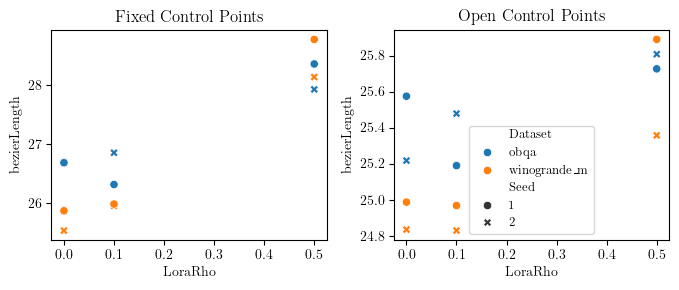

In [16]:
from copy import deepcopy
df_length = df_clean[df_clean['CpFix'] != '[1]']
df_length = df_length[df_length['LoraMode'] == 'A(t)B(t)']
ids = deepcopy(variable_idx)
ids.remove('CpFix')
df_fix = df_length[df_length['CpFix'] == "[1, 0, 1]"].set_index(ids)
df_open = df_length[df_length['CpFix'] == "[0, 0, 0]"].set_index(ids)


fig, ax = plt.subplots(1,2, figsize=(7,3))
sns.scatterplot(data=df_fix.reset_index(), x='LoraRho', y='bezierLength', hue='Dataset', style='Seed', ax=ax[0], legend=False)
sns.scatterplot(data=df_open.reset_index(), x='LoraRho', y='bezierLength', hue='Dataset', style='Seed', ax=ax[1])
ax[0].set_title("Fixed Control Points")
ax[1].set_title("Open Control Points")
plt.tight_layout()

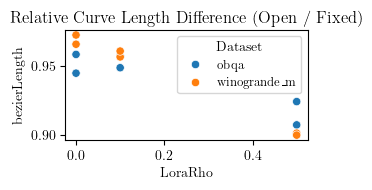

In [17]:
df_rel_diff = df_open['bezierLength'] / df_fix['bezierLength']

ax = sns.scatterplot(data=df_rel_diff.reset_index(), x='LoraRho', y='bezierLength', hue='Dataset')
ax.set_title("Relative Curve Length Difference (Open / Fixed)")
plt.tight_layout()

#### acc compare Entropy Scale

In [21]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
# df_subset = df_subset[df_subset['Dataset']!='ARC-Easy']
# df_subset = df_subset[df_subset['Dataset']!='winogrande_s']
# df_subset = df_subset[(df_subset['LoraRho']==0.) | (df_subset['LoraRho']==0.1) | (df_subset['LoraRho']==0.5)]
# df_subset = df_subset[((df_subset['Tsample']=='per_leaf') &  (df_subset['Model'].str.startswith("Flat_k")) & (df_subset['LoraMode'] == "A(t)B(t)")) | (~(df_subset['Model'].str.startswith("Flat_k")))]
# df_subset = df_subset[~((df_subset['Dataset'] == "winogrande_m") & (df_subset['Model'].str.startswith("Flat_k")) & (df_subset['LoraRho'] == 0.1))]
# df_subset = df_subset[df_subset['EntropyMaxScale']!=2.5]
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
idx = ['Dataset', 'LoraMode', 'DegFreedom', 'CpFix', 'LoraRho']
df_subset.groupby(idx)[['acc', 'nll', 'ece']].mean()

acc       nll  \
Dataset      LoraMode DegFreedom CpFix     LoraRho                       
obqa         A(t)B(t) 1          [1]       0.0      0.905000  0.267490   
                                           0.1      0.912000  0.226578   
                                           0.5      0.907000  0.257908   
                      3          [0, 0, 0] 0.0      0.908000  0.248269   
                                           0.1      0.901000  0.270385   
                                           0.5      0.918000  0.252445   
                                 [1, 0, 1] 0.0      0.911000  0.256860   
                                           0.1      0.910000  0.231230   
                                           0.5      0.922000  0.257773   
             Asd(t)B  1          [1]       0.0      0.909000  0.265812   
                                           0.1      0.914000  0.232572   
                                           0.5      0.907000  0.251183   
                      3          [0, 0, 0] 0.0      0.912000  0.249494   
                                           0.1      0.916000  0.230124   
                                           0.5      0.911000  0.254408   
winogrande_m A(t)B(t) 1          [1]       0.0      0.807917  0.436633   
                                           0.1      0.800417  0.456057   
                                           0.5      0.818750  0.426393   
                      3          [0, 0, 0] 0.0      0.802083  0.457367   
                                           0.1      0.812500  0.448875   
                                           0.5      0.814583  0.425282   
                                 [1, 0, 1] 0.0      0.813333  0.461527   
                                           0.1      0.805000  0.458472   
                                           0.5      0.827083  0.417484   
             Asd(t)B  1          [1]       0.0      0.813333  0.431361   
                                           0.1      0.800417  0.458303   
                                           0.5      0.825417  0.426075   
                      3          [0, 0, 0] 0.0      0.806667  0.442788   
                                           0.1      0.807500  0.447952   
                                           0.5      0.825417  0.425332   

                                                         ece  
Dataset      LoraMode DegFreedom CpFix     LoraRho            
obqa         A(t)B(t) 1          [1]       0.0      0.028242  
                                           0.1      0.034963  
                                           0.5      0.033305  
                      3          [0, 0, 0] 0.0      0.033065  
                                           0.1      0.031969  
                                           0.5      0.033020  
                                 [1, 0, 1] 0.0      0.036763  
                                           0.1      0.029367  
                                           0.5      0.036976  
             Asd(t)B  1          [1]       0.0      0.036831  
                                           0.1      0.020924  
                                           0.5      0.035511  
                      3          [0, 0, 0] 0.0      0.030120  
                                           0.1      0.024384  
                                           0.5      0.031456  
winogrande_m A(t)B(t) 1          [1]       0.0      0.038755  
                                           0.1      0.053986  
                                           0.5      0.066116  
                      3          [0, 0, 0] 0.0      0.057935  
                                           0.1      0.060982  
                                           0.5      0.052327  
                                 [1, 0, 1] 0.0      0.073616  
                                           0.1      0.066751  
                                           0.5      0.065455  
             Asd(t)B  1          [1]       0.0    

### PPD vs Uniform

We run Modeconnected exp with A(t)B(t) and [1,0,0,1,0, 0,1] fixed control points. 
Then the pretrained models are used as DE members and compared against curve training with these fixed control points

In [3]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in ["qd3vby8c", "zyk44mta", "6uh01z19"]: # winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC_seg/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            CurveSpace=len(mp['cp_fix']),
            CpFix=str(mp['cp_fix']),
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegment=mp.get('curve_segment', len(mp['cp_fix'])),
            OpenEndSegment=mp.get('independent_connected', False),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        # add DE   
        _res = deepcopy(res)
        _res['BmaMode'] = "DE"
        _res['acc'] = run.summary.get(f"DE_acc", -np.inf)
        _res['ece'] = run.summary.get(f"DE_ece", -np.inf)
        _res['ll'] = run.summary.get(f"DE_ll", -np.inf)
        results.append(_res)
        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)

        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)
 
df = pd.DataFrame(results)
df.describe().T

6uh01z19: 100%|██████████| 40/40 [00:00<00:00, 155.90it/s, northern-sweep-1] 


,count,mean,std,min,25%,50%,75%,max
CurveSpace,480.0,7.000000,3.745561e+00,3.000000,4.500000,6.000000,8.500000,13.000000
Jitter,480.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
Seed,480.0,2105.250000,3.410609e+03,1.000000,15.250000,210.000000,2300.000000,8000.000000
WeightDecay,480.0,0.001000,4.341333e-19,0.001000,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,480.0,-1.000000,0.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
EntropyMaxScale,480.0,-1.000000,0.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,480.0,10000.000000,0.000000e+00,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,480.0,8.000000,0.000000e+00,8.000000,8.000000,8.000000,8.000000,8.000000
Gravity,480.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
EnergyWeakening,480.0,1.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000


In [4]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [13  7  5  3]
CpFix ['[1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]' '[1, 0, 0, 1, 0, 0, 1]'
 '[1, 0, 1, 0, 1]' '[1, 1, 1]']
Jitter [0]
Seed [8000  400   20    1]
WeightDecay [0.001]
Dataset ['ARC-Easy' 'ARC-Challenge' 'winogrande_s' 'obqa' 'winogrande_m']
BmaMode ['PPD' 'DE' 'PPD Uniform']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_all']
LoraRho [0.5  0.25]
LoraRhoS [0]
RhoFrequency [50]
CurveSegment [3 2 1]
OpenEndSegment [False]

Experiment differs in ['CurveSpace', 'CpFix', 'Dataset', 'BmaMode', 'LoraRho', 'CurveSegment'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [5]:
# Build Config label
df_subset = df_clean.copy()

# df_subset = df_subset.sort_values(by='Config')

# Melt all lowercase-named columns → long form with Metric column
# lower_cols = [c for c in df_subset.columns if c[0].islower()]
# id_cols = [c for c in df_subset.columns if c not in lower_cols]
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: f"k={r['CurveSpace']}, rho={r['LoraRho']}", axis=1)

col_order = df_subset['Dataset'].unique()
col_order.sort()


/tmp/ipykernel_3628080/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale c

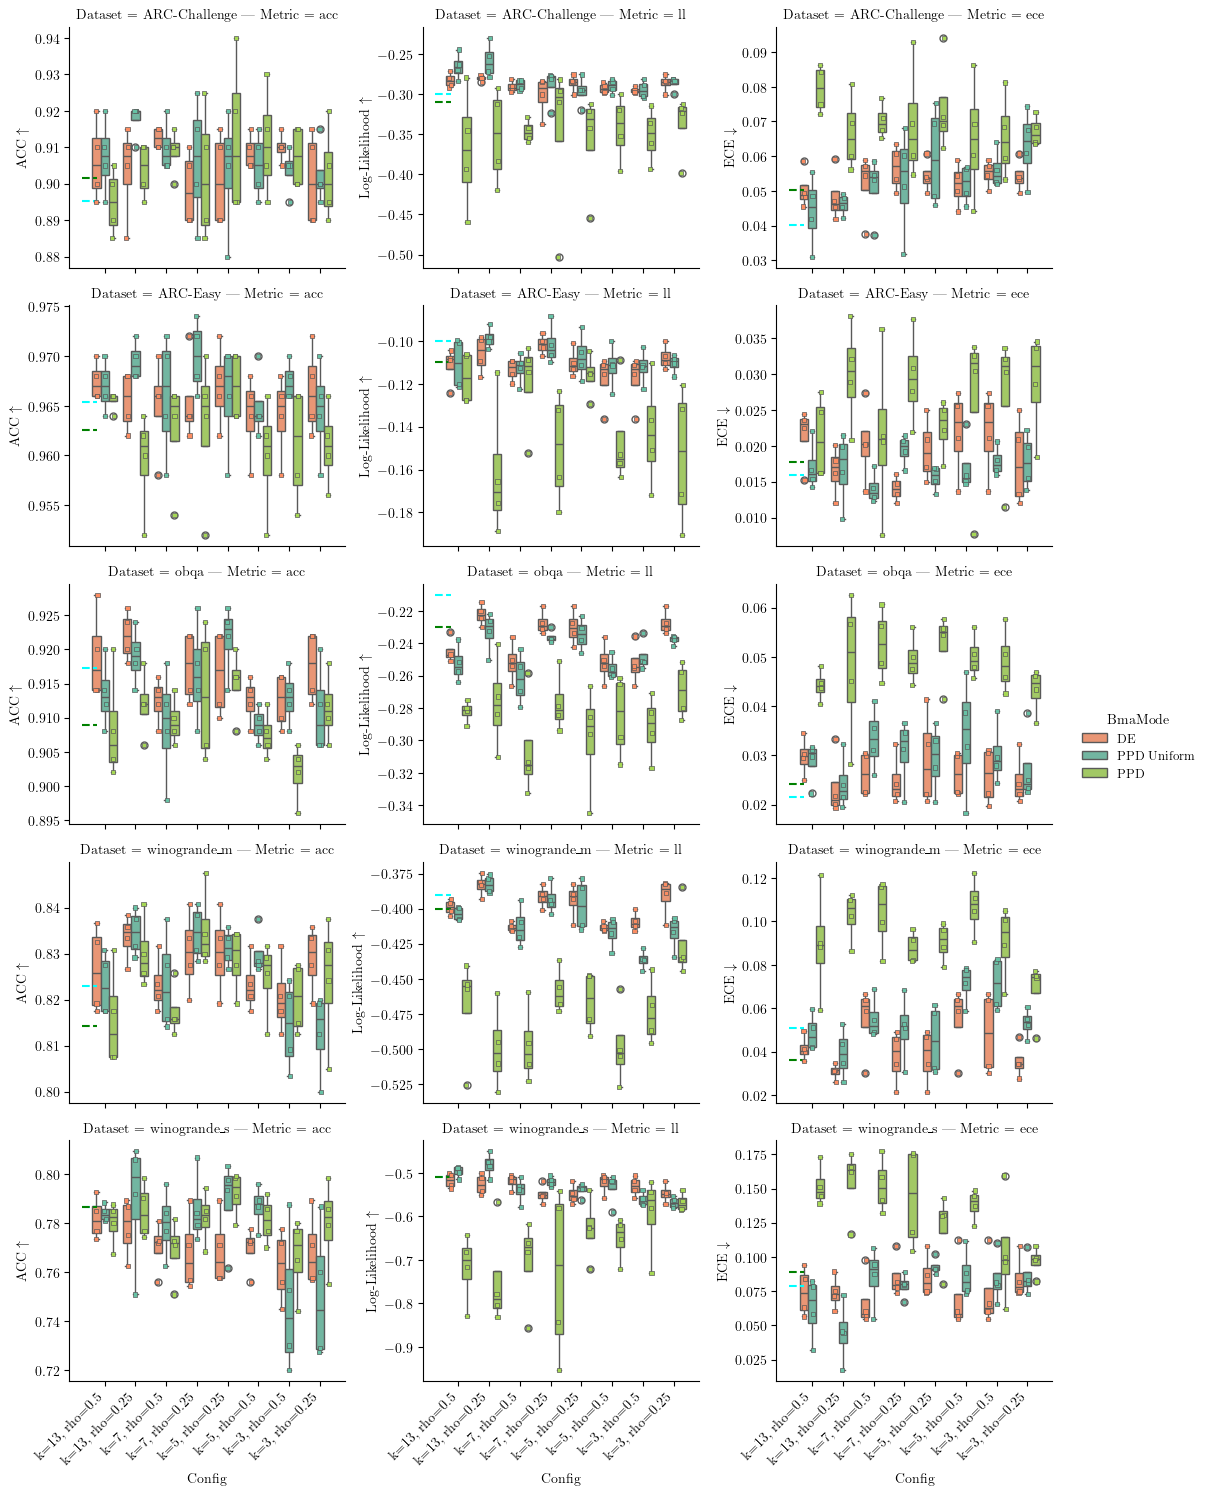

In [6]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':  {'MLE': 78.86, 'MAP': 78.94, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':      {'MLE': 95.60, 'MAP': 95.73, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':  {'MLE': 82.30, 'MAP': 82.09, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':          {'MLE': 92.25, 'MAP': 91.72, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':         {'MLE': 89.06, 'MAP': 89.04, 'BLoB': 89.05, 'ScalaBL': 88.48},
}
# Reference NLL values (our ll = -nll, so ref_ll = -ref_nll)
ref_nll = {
    'boolq':         {'MLE': 0.25, 'MAP': 0.25, 'BLoB': 0.23, 'ScalaBL': 0.24},
    'ARC-Easy':      {'MLE': 0.44, 'MAP': 0.43, 'BLoB': 0.10, 'ScalaBL': 0.11},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.05, 'BLoB': 0.30, 'ScalaBL': 0.31},
    'obqa':          {'MLE': 0.38, 'MAP': 0.39, 'BLoB': 0.21, 'ScalaBL': 0.23},
    'winogrande_s':  {'MLE': 1.94, 'MAP': 1.88, 'BLoB': 0.51, 'ScalaBL': 0.51},
    'winogrande_m':  {'MLE': 1.20, 'MAP': 1.27, 'BLoB': 0.39, 'ScalaBL': 0.40},
}
# Reference ECE values (in %, divide by 100)
ref_ece = {
    'winogrande_s':  {'MLE': 20.14, 'MAP': 19.99, 'BLoB': 7.88,  'ScalaBL': 8.88},
    'ARC-Challenge': {'MLE': 10.11, 'MAP': 10.54, 'BLoB': 4.03,  'ScalaBL': 5.03},
    'ARC-Easy':      {'MLE': 4.17,  'MAP': 4.08,  'BLoB': 1.60,  'ScalaBL': 1.78},
    'winogrande_m':  {'MLE': 16.10, 'MAP': 16.42, 'BLoB': 5.08,  'ScalaBL': 3.64},
    'obqa':          {'MLE': 6.40,  'MAP': 6.61,  'BLoB': 2.16,  'ScalaBL': 2.43},
    'boolq':         {'MLE': 3.79,  'MAP': 3.81,  'BLoB': 1.40,  'ScalaBL': 1.96},
}

# Melt to long form: acc, ll, ece → Metric + value
# id_cols = [c for c in df_subset.columns if c not in ('acc', 'll', 'ece')]
# df_plot = df_subset.melt(id_vars=id_cols, value_vars=['acc', 'll', 'ece'], var_name='Metric', value_name='value')

# hue_order = df_plot['BmaMode'].unique()
hue_order = ['DE', 'PPD Uniform', 'PPD']
# Single color for all hue levels
cmap = sns.color_palette("Set2")
hue_palette = {'DE': cmap[1], 'PPD Uniform': cmap[0], 'PPD': cmap[4]}

metric_order = ['acc', 'll', 'ece']

g = sns.catplot(
    data=df_plot, x='Config', y='value', hue='BmaMode', kind='box',
    row='Dataset', col='Metric', palette=hue_palette, sharey=False,
    height=figsize[1] * 1.5, row_order=col_order, col_order=metric_order,
    hue_order=hue_order, aspect=1.2
)

# Overlay strip plots
for (ds, metric), ax in g.axes_dict.items():
    sns.stripplot(
        data=df_plot[(df_plot['Dataset'] == ds) & (df_plot['Metric'] == metric)],
        x='Config', y='value', hue='BmaMode',
        ax=ax, palette=hue_palette, dodge=True,
        edgecolor='gray', linewidth=0.5, size=3, marker='s',
        hue_order=hue_order, legend=False
    )

# Set y-axis labels per metric column
ylabel_map = {'acc': r'ACC $\uparrow$', 'll': r'Log-Likelihood $\uparrow$', 'ece': r'ECE $\downarrow$'}
for col_idx, metric in enumerate(metric_order):
    for ax in g.axes[:, col_idx]:
        ax.set_ylabel(ylabel_map[metric])

# Draw reference lines for all three metrics
ref_map = {
    'acc': (ref_acc, lambda v: v / 100),
    'll':  (ref_nll, lambda v: -v),       # ll = -nll
    'ece': (ref_ece, lambda v: v / 100),
}
for col_idx, metric in enumerate(metric_order):
    ref_dict, transform = ref_map[metric]
    for row_idx, ds in enumerate(col_order):
        if ds not in ref_dict:
            continue
        ax = g.axes[row_idx, col_idx]
        tick = -0.5
        # ax.hlines(y=transform(ref_dict[ds]['MLE']),     xmin=tick-0.25, xmax=tick+0.25,
        #           colors='blue',  linestyles='--', lw=2.5, label='MLE')
        ax.hlines(y=transform(ref_dict[ds]['BLoB']),    xmin=tick-0.25, xmax=tick+0.25,
                  colors='cyan',  linestyles='--', lw=1.5, label='BLoB')
        ax.hlines(y=transform(ref_dict[ds]['ScalaBL']), xmin=tick-0.25, xmax=tick+0.25,
                  colors='green', linestyles='--', lw=1.5, label='ScalaBL')
        # ax.hlines(y=transform(ref_dict[ds]['MAP']),     xmin=tick-0.25, xmax=tick+0.25,
        #           colors='red',   linestyles='--', lw=1.5, label='MAP')

# Rotate x-tick labels on last row
for ax in g.axes[-1, :].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

g.tight_layout()


/tmp/ipykernel_3628080/742950105.py:51: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/742950105.py:51: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/742950105.py:51: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/742950105.py:51: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/742950105.py:51: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3628080/742950105.py:51: FutureWarning: Use "auto" to set automatic grayscale colors.

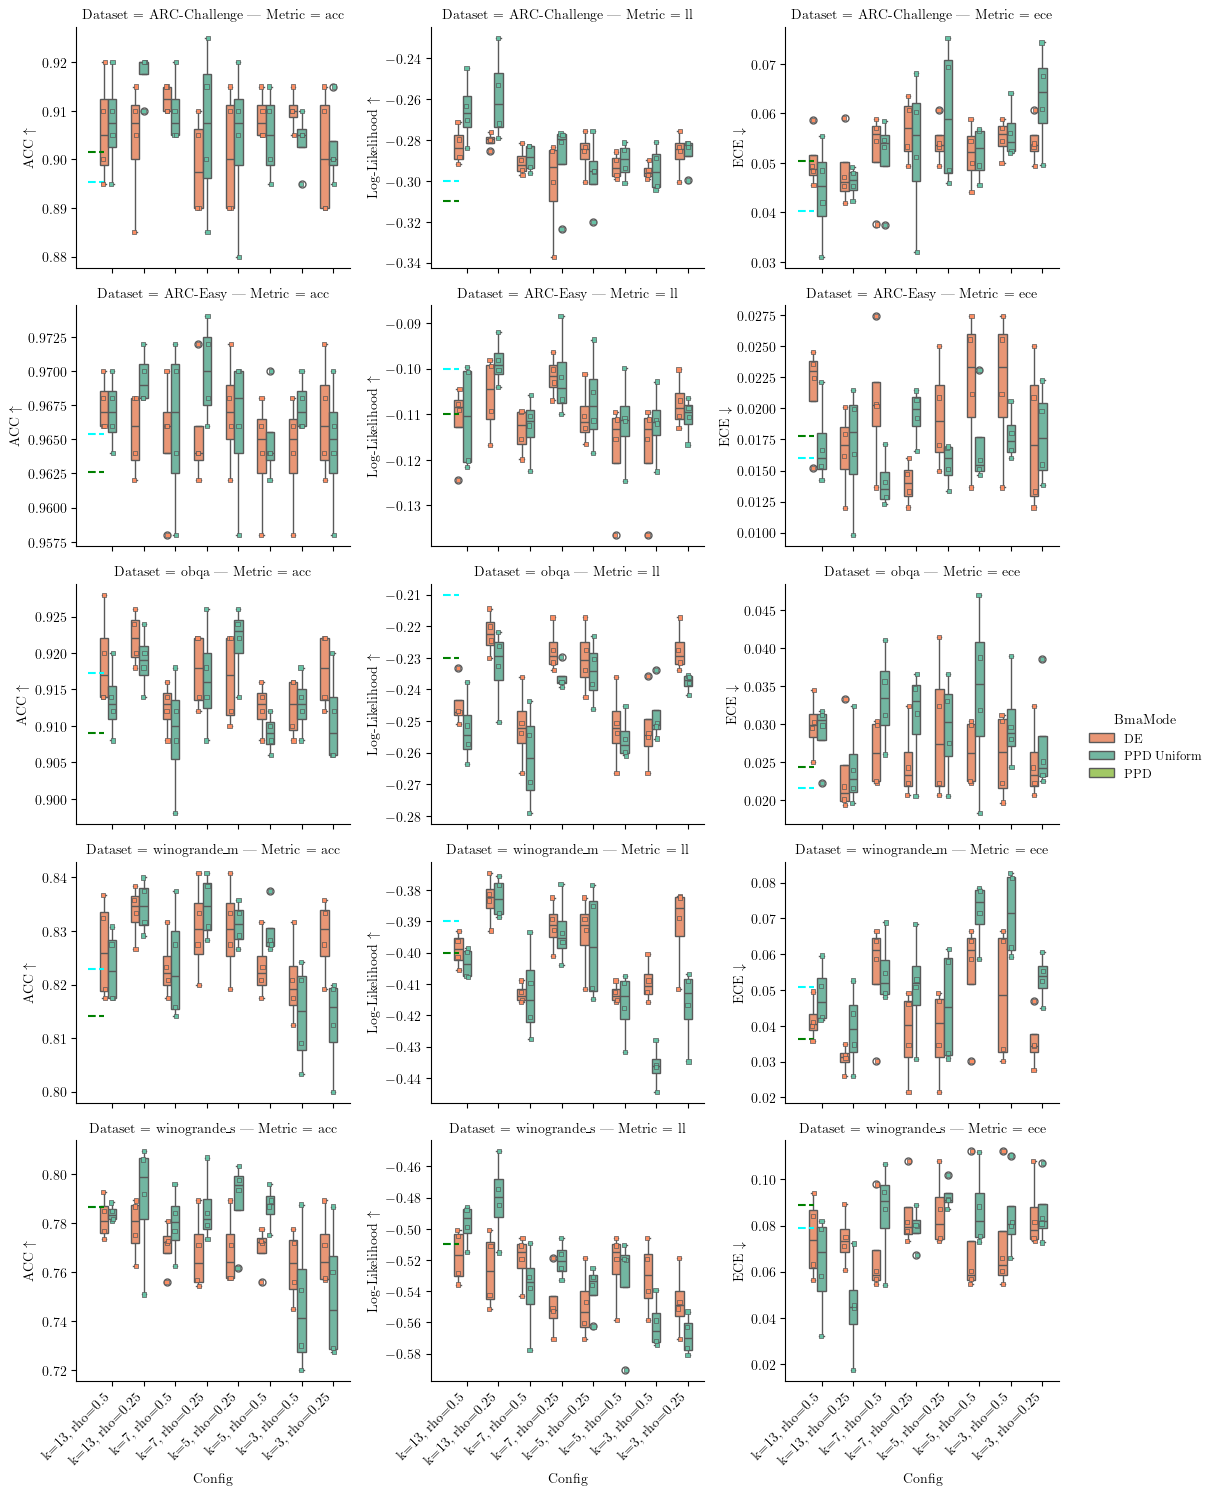

In [7]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':  {'MLE': 78.86, 'MAP': 78.94, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':      {'MLE': 95.60, 'MAP': 95.73, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':  {'MLE': 82.30, 'MAP': 82.09, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':          {'MLE': 92.25, 'MAP': 91.72, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':         {'MLE': 89.06, 'MAP': 89.04, 'BLoB': 89.05, 'ScalaBL': 88.48},
}
# Reference NLL values (our ll = -nll, so ref_ll = -ref_nll)
ref_nll = {
    'boolq':         {'MLE': 0.25, 'MAP': 0.25, 'BLoB': 0.23, 'ScalaBL': 0.24},
    'ARC-Easy':      {'MLE': 0.44, 'MAP': 0.43, 'BLoB': 0.10, 'ScalaBL': 0.11},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.05, 'BLoB': 0.30, 'ScalaBL': 0.31},
    'obqa':          {'MLE': 0.38, 'MAP': 0.39, 'BLoB': 0.21, 'ScalaBL': 0.23},
    'winogrande_s':  {'MLE': 1.94, 'MAP': 1.88, 'BLoB': 0.51, 'ScalaBL': 0.51},
    'winogrande_m':  {'MLE': 1.20, 'MAP': 1.27, 'BLoB': 0.39, 'ScalaBL': 0.40},
}
# Reference ECE values (in %, divide by 100)
ref_ece = {
    'winogrande_s':  {'MLE': 20.14, 'MAP': 19.99, 'BLoB': 7.88,  'ScalaBL': 8.88},
    'ARC-Challenge': {'MLE': 10.11, 'MAP': 10.54, 'BLoB': 4.03,  'ScalaBL': 5.03},
    'ARC-Easy':      {'MLE': 4.17,  'MAP': 4.08,  'BLoB': 1.60,  'ScalaBL': 1.78},
    'winogrande_m':  {'MLE': 16.10, 'MAP': 16.42, 'BLoB': 5.08,  'ScalaBL': 3.64},
    'obqa':          {'MLE': 6.40,  'MAP': 6.61,  'BLoB': 2.16,  'ScalaBL': 2.43},
    'boolq':         {'MLE': 3.79,  'MAP': 3.81,  'BLoB': 1.40,  'ScalaBL': 1.96},
}

# Melt to long form: acc, ll, ece → Metric + value
# id_cols = [c for c in df_subset.columns if c not in ('acc', 'll', 'ece')]
# df_plot = df_subset.melt(id_vars=id_cols, value_vars=['acc', 'll', 'ece'], var_name='Metric', value_name='value')
df_plot = df_plot[df_plot['BmaMode'] != 'PPD']

# hue_order = df_plot['BmaMode'].unique()
hue_order = ['DE', 'PPD Uniform', 'PPD']
# Single color for all hue levels
cmap = sns.color_palette("Set2")
hue_palette = {'DE': cmap[1], 'PPD Uniform': cmap[0], 'PPD': cmap[4]}

metric_order = ['acc', 'll', 'ece']

g = sns.catplot(
    data=df_plot, x='Config', y='value', hue='BmaMode', kind='box',
    row='Dataset', col='Metric', palette=hue_palette, sharey=False,
    height=figsize[1] * 1.5, row_order=col_order, col_order=metric_order,
    hue_order=hue_order, aspect=1.2
)

# Overlay strip plots
for (ds, metric), ax in g.axes_dict.items():
    sns.stripplot(
        data=df_plot[(df_plot['Dataset'] == ds) & (df_plot['Metric'] == metric)],
        x='Config', y='value', hue='BmaMode',
        ax=ax, palette=hue_palette, dodge=True,
        edgecolor='gray', linewidth=0.5, size=3, marker='s',
        hue_order=hue_order, legend=False
    )

# Set y-axis labels per metric column
ylabel_map = {'acc': r'ACC $\uparrow$', 'll': r'Log-Likelihood $\uparrow$', 'ece': r'ECE $\downarrow$'}
for col_idx, metric in enumerate(metric_order):
    for ax in g.axes[:, col_idx]:
        ax.set_ylabel(ylabel_map[metric])

# Draw reference lines for all three metrics
ref_map = {
    'acc': (ref_acc, lambda v: v / 100),
    'll':  (ref_nll, lambda v: -v),       # ll = -nll
    'ece': (ref_ece, lambda v: v / 100),
}
for col_idx, metric in enumerate(metric_order):
    ref_dict, transform = ref_map[metric]
    for row_idx, ds in enumerate(col_order):
        if ds not in ref_dict:
            continue
        ax = g.axes[row_idx, col_idx]
        tick = -0.5
        # ax.hlines(y=transform(ref_dict[ds]['MLE']),     xmin=tick-0.25, xmax=tick+0.25,
        #           colors='blue',  linestyles='--', lw=2.5, label='MLE')
        ax.hlines(y=transform(ref_dict[ds]['BLoB']),    xmin=tick-0.25, xmax=tick+0.25,
                  colors='cyan',  linestyles='--', lw=1.5, label='BLoB')
        ax.hlines(y=transform(ref_dict[ds]['ScalaBL']), xmin=tick-0.25, xmax=tick+0.25,
                  colors='green', linestyles='--', lw=1.5, label='ScalaBL')
        # ax.hlines(y=transform(ref_dict[ds]['MAP']),     xmin=tick-0.25, xmax=tick+0.25,
        #           colors='red',   linestyles='--', lw=1.5, label='MAP')

# Rotate x-tick labels on last row
for ax in g.axes[-1, :].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

g.tight_layout()


### Bezier Segments with independent pretraining and MLE results

We run Modeconnected exp with A(t)B(t) and [1,0,0,1,0,0,1], [1,0,0,1,0,0,1,0,0,1,0,0,1], [1,0,1,0,1] fixed control points. 
Then the pretrained models are used as DE members and compared against curve training with these fixed control points

In [ ]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in ["qd3vby8c", "zyk44mta"]: # winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC_seg/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            CurveSpace=len(mp['cp_fix']),
            CpFix=str(mp['cp_fix']),
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegment=mp.get('curve_segment', len(mp['cp_fix'])),
            OpenEndSegment=mp.get('independent_connected', False),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        # add DE   
        _res = deepcopy(res)
        _res['BmaMode'] = "DE"
        _res['acc'] = run.summary.get(f"DE_acc", -np.inf)
        _res['ece'] = run.summary.get(f"DE_ece", -np.inf)
        _res['ll'] = run.summary.get(f"DE_ll", -np.inf)
        results.append(_res)
        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)

        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)

        for i in mp['cp_fix']:
            if i != False
 
df = pd.DataFrame(results)
df.describe().T

zyk44mta: 100%|██████████| 40/40 [00:00<00:00, 172.78it/s, cerulean-sweep-1] 


Skipping true-sweep-3 because it is not finished


,count,mean,std,min,25%,50%,75%,max
CurveSpace,357.0,8.361345,3.404552e+00,5.000000,5.000000,7.000000,13.000000,13.000000
Jitter,357.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
Seed,357.0,2119.579832,3.422534e+03,1.000000,1.000000,20.000000,8000.000000,8000.000000
WeightDecay,357.0,0.001000,2.171448e-19,0.001000,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,357.0,-1.000000,0.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
EntropyMaxScale,357.0,-1.000000,0.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,357.0,10000.000000,0.000000e+00,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,357.0,8.000000,0.000000e+00,8.000000,8.000000,8.000000,8.000000,8.000000
Gravity,357.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
EnergyWeakening,357.0,1.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [13  7  5]
CpFix ['[1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]' '[1, 0, 0, 1, 0, 0, 1]'
 '[1, 0, 1, 0, 1]']
Jitter [0]
Seed [8000  400   20    1]
WeightDecay [0.001]
Dataset ['ARC-Easy' 'ARC-Challenge' 'winogrande_s' 'obqa' 'winogrande_m']
BmaMode ['PPD' 'DE' 'PPD Uniform']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_all']
LoraRho [0.5  0.25]
LoraRhoS [0]
RhoFrequency [50]
CurveSegment [3 2]
OpenEndSegment [False]

Experiment differs in ['CurveSpace', 'CpFix', 'Dataset', 'BmaMode', 'LoraRho', 'CurveSegment'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [ ]:
# Build Config label
df_subset = df_clean.copy()

# df_subset = df_subset.sort_values(by='Config')

# Melt all lowercase-named columns → long form with Metric column
# lower_cols = [c for c in df_subset.columns if c[0].islower()]
# id_cols = [c for c in df_subset.columns if c not in lower_cols]
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: f"k={r['CurveSpace']}, rho={r['LoraRho']}", axis=1)

col_order = df_subset['Dataset'].unique()
col_order.sort()


/tmp/ipykernel_3576707/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3576707/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3576707/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3576707/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3576707/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_3576707/1423725297.py:50: FutureWarning: Use "auto" to set automatic grayscale c

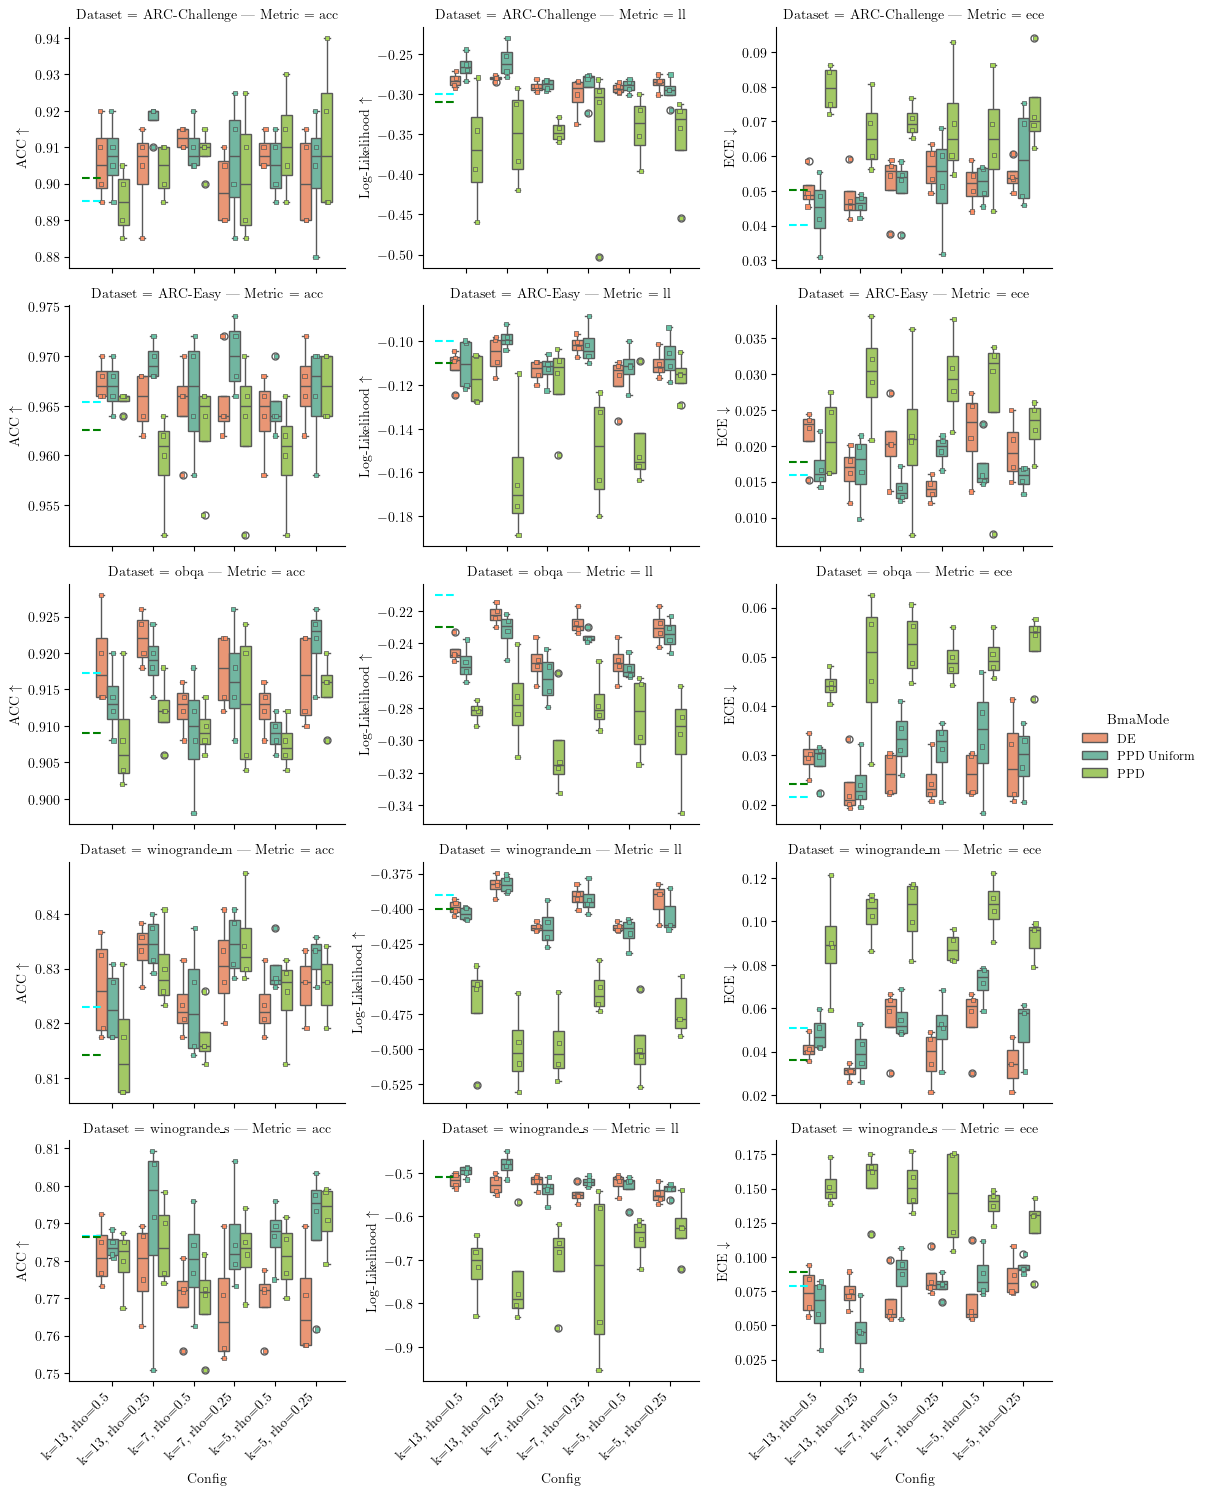

In [ ]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':  {'MLE': 78.86, 'MAP': 78.94, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':      {'MLE': 95.60, 'MAP': 95.73, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':  {'MLE': 82.30, 'MAP': 82.09, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':          {'MLE': 92.25, 'MAP': 91.72, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':         {'MLE': 89.06, 'MAP': 89.04, 'BLoB': 89.05, 'ScalaBL': 88.48},
}
# Reference NLL values (our ll = -nll, so ref_ll = -ref_nll)
ref_nll = {
    'boolq':         {'MLE': 0.25, 'MAP': 0.25, 'BLoB': 0.23, 'ScalaBL': 0.24},
    'ARC-Easy':      {'MLE': 0.44, 'MAP': 0.43, 'BLoB': 0.10, 'ScalaBL': 0.11},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.05, 'BLoB': 0.30, 'ScalaBL': 0.31},
    'obqa':          {'MLE': 0.38, 'MAP': 0.39, 'BLoB': 0.21, 'ScalaBL': 0.23},
    'winogrande_s':  {'MLE': 1.94, 'MAP': 1.88, 'BLoB': 0.51, 'ScalaBL': 0.51},
    'winogrande_m':  {'MLE': 1.20, 'MAP': 1.27, 'BLoB': 0.39, 'ScalaBL': 0.40},
}
# Reference ECE values (in %, divide by 100)
ref_ece = {
    'winogrande_s':  {'MLE': 20.14, 'MAP': 19.99, 'BLoB': 7.88,  'ScalaBL': 8.88},
    'ARC-Challenge': {'MLE': 10.11, 'MAP': 10.54, 'BLoB': 4.03,  'ScalaBL': 5.03},
    'ARC-Easy':      {'MLE': 4.17,  'MAP': 4.08,  'BLoB': 1.60,  'ScalaBL': 1.78},
    'winogrande_m':  {'MLE': 16.10, 'MAP': 16.42, 'BLoB': 5.08,  'ScalaBL': 3.64},
    'obqa':          {'MLE': 6.40,  'MAP': 6.61,  'BLoB': 2.16,  'ScalaBL': 2.43},
    'boolq':         {'MLE': 3.79,  'MAP': 3.81,  'BLoB': 1.40,  'ScalaBL': 1.96},
}

# Melt to long form: acc, ll, ece → Metric + value
# id_cols = [c for c in df_subset.columns if c not in ('acc', 'll', 'ece')]
# df_plot = df_subset.melt(id_vars=id_cols, value_vars=['acc', 'll', 'ece'], var_name='Metric', value_name='value')

# hue_order = df_plot['BmaMode'].unique()
hue_order = ['DE', 'PPD Uniform', 'PPD']
# Single color for all hue levels
cmap = sns.color_palette("Set2")
hue_palette = {'DE': cmap[1], 'PPD Uniform': cmap[0], 'PPD': cmap[4]}

metric_order = ['acc', 'll', 'ece']

g = sns.catplot(
    data=df_plot, x='Config', y='value', hue='BmaMode', kind='box',
    row='Dataset', col='Metric', palette=hue_palette, sharey=False,
    height=figsize[1] * 1.5, row_order=col_order, col_order=metric_order,
    hue_order=hue_order, aspect=1.2
)

# Overlay strip plots
for (ds, metric), ax in g.axes_dict.items():
    sns.stripplot(
        data=df_plot[(df_plot['Dataset'] == ds) & (df_plot['Metric'] == metric)],
        x='Config', y='value', hue='BmaMode',
        ax=ax, palette=hue_palette, dodge=True,
        edgecolor='gray', linewidth=0.5, size=3, marker='s',
        hue_order=hue_order, legend=False
    )

# Set y-axis labels per metric column
ylabel_map = {'acc': r'ACC $\uparrow$', 'll': r'Log-Likelihood $\uparrow$', 'ece': r'ECE $\downarrow$'}
for col_idx, metric in enumerate(metric_order):
    for ax in g.axes[:, col_idx]:
        ax.set_ylabel(ylabel_map[metric])

# Draw reference lines for all three metrics
ref_map = {
    'acc': (ref_acc, lambda v: v / 100),
    'll':  (ref_nll, lambda v: -v),       # ll = -nll
    'ece': (ref_ece, lambda v: v / 100),
}
for col_idx, metric in enumerate(metric_order):
    ref_dict, transform = ref_map[metric]
    for row_idx, ds in enumerate(col_order):
        if ds not in ref_dict:
            continue
        ax = g.axes[row_idx, col_idx]
        tick = -0.5
        # ax.hlines(y=transform(ref_dict[ds]['MLE']),     xmin=tick-0.25, xmax=tick+0.25,
        #           colors='blue',  linestyles='--', lw=2.5, label='MLE')
        ax.hlines(y=transform(ref_dict[ds]['BLoB']),    xmin=tick-0.25, xmax=tick+0.25,
                  colors='cyan',  linestyles='--', lw=1.5, label='BLoB')
        ax.hlines(y=transform(ref_dict[ds]['ScalaBL']), xmin=tick-0.25, xmax=tick+0.25,
                  colors='green', linestyles='--', lw=1.5, label='ScalaBL')
        # ax.hlines(y=transform(ref_dict[ds]['MAP']),     xmin=tick-0.25, xmax=tick+0.25,
        #           colors='red',   linestyles='--', lw=1.5, label='MAP')

# Rotate x-tick labels on last row
for ax in g.axes[-1, :].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

g.tight_layout()


### Load sampling results

In [3]:
from pathlib import Path

sampling_files = [
    "result/sampling/wino_m_psmile.csv",
    "result/sampling/wino_m_sghmc.csv",
    "result/sampling/wino_s_psmile.csv",
    "result/sampling/wino_s_sghmc.csv",
    "result/sampling/lora_obqa_psmile_replications.csv",
    "result/sampling/lora_arc_easy_psmile_replications.csv",
    "result/sampling/lora_arc_chall_psmile_replications.csv",
]

rows = []
for file_path in sampling_files:
    df_s = pd.read_csv(file_path)

    # Determine dataset and selection logic
    fname = Path(file_path).name
    if "obqa" in fname:
        dataset = "obqa"
        step_size = 0.0005
    elif "arc_easy" in fname:
        dataset = "ARC-Easy"
        step_size = 0.0005
    elif "arc_chall" in fname:
        dataset = "ARC-Challenge"
        step_size = 0.0005
    else:
        # Original logic for winogrande files
        dataset = "winogrande_m" if "wino_m" in file_path else "winogrande_s"
        ref = df_s[df_s["rng"] == 400]
        if ref.empty:
            print(f"Skipping {file_path}: no rng=400 row found")
            continue
        step_size = ref.iloc[0]["training_sampler_step_size"]

    # Filter by the chosen step size
    df_sel = df_s[df_s["training_sampler_step_size"] == step_size].copy()

    # Build the same core structure used in our extracted dataframe
    for _, r in df_sel.iterrows():
        rows.append(
            {
                "Id": str(r.get("experiment", Path(file_path).stem)),
                "CurveSpace": -1,
                "CpFix": "sampling",
                "NumPretrained": -1,
                "Jitter": -1,
                "Seed": int(r.get("rng", -1)) if pd.notna(r.get("rng", np.nan)) else -1,
                "WeightDecay": -1,
                "Dataset": dataset,
                "BmaMode": "Sampling",
                "DS_Sampling": str(r.get("training_sampler_name", "noisysmile")),
                "DS_Mode": "sampler",
                "DS_WindowSize": -1,
                "EntropyMaxScale": -1,
                "NumSteps": -1,
                "LoraMode": "Sampling",
                "CurveMode": "Sampling",
                "LoraRank": -1,
                "RegularizationMode": False,
                "Gravity": -1,
                "EnergyWeakening": -1,
                "Tsample": "sampling",
                "LoraRho": -1,
                "LoraRhoS": -1,
                "RhoFrequency": -1,
                "CurveSegmentDegree": -1,
                "NCurveSegment": 0,
                "OpenEndSegment": False,
                "bezierLength": 0,
                "acc": r.get("PredPerf_sampling_bma_accuracy", np.nan),
                "ece": r.get("Calibration_sampling_calibration_error", np.nan),
                "ll": r.get("LPPD_sampling_LPPD", np.nan),
                "test_mean_entropy_ppd": np.nan,
                "test_mutual_information_ppd": np.nan,
                "test_std_entropy_along_curve": np.nan,
                "test_mean_entropy_along_curve": np.nan,
                "Method": str(r.get("training_sampler_name", "noisysmile")),
                "SamplerStepSize": step_size,
                "SourceFile": fname,
            }
        )

    print(f"{fname}: target_step_size={step_size}, rows_kept={len(df_sel)}")

df_sampling = pd.DataFrame(rows)

out_path = "result/sampling/sampling_merged_stepfiltered.csv"
df_sampling.to_csv(out_path, index=False)
print(f"Saved merged sampling dataframe to {out_path} with {len(df_sampling)} rows")

df_sampling = df_sampling.melt(
    id_vars=[c for c in df_sampling.columns if c not in ["acc", "ll", "ece"]],
    value_vars=["acc", "ll", "ece"],
    var_name="Metric",
    value_name="value",
)
df_sampling.dropna(subset=['value'], inplace=True)

def get_sampling_model_name(m):
    if m == "noisysmile" or "noisysmile" in str(m):
        return "Sampling-PSMILE"
    return "Sampling-SGHMC"

df_sampling["Model"] = df_sampling["Method"].apply(get_sampling_model_name)
df_sampling["NCurveSegment"] = 0

df_sampling.head()

wino_m_psmile.csv: target_step_size=0.0001, rows_kept=5
wino_m_sghmc.csv: target_step_size=5e-06, rows_kept=5
wino_s_psmile.csv: target_step_size=0.01, rows_kept=5
wino_s_sghmc.csv: target_step_size=0.0001, rows_kept=5
lora_obqa_psmile_replications.csv: target_step_size=0.0005, rows_kept=8
lora_arc_easy_psmile_replications.csv: target_step_size=0.0005, rows_kept=8
lora_arc_chall_psmile_replications.csv: target_step_size=0.0005, rows_kept=5
Saved merged sampling dataframe to result/sampling/sampling_merged_stepfiltered.csv with 41 rows


,Id,CurveSpace,CpFix,NumPretrained,Jitter,Seed,WeightDecay,Dataset,BmaMode,DS_Sampling,...,test_mean_entropy_ppd,test_mutual_information_ppd,test_std_entropy_along_curve,test_mean_entropy_along_curve,Method,SamplerStepSize,SourceFile,Metric,value,Model
0,lora_wino_m_div5_20260320-063059,-1,sampling,-1,-1,40,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.830833,Sampling-PSMILE
1,lora_wino_m_div5_20260320-051752,-1,sampling,-1,-1,20,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.831667,Sampling-PSMILE
2,lora_wino_m_div5_20260320-074403,-1,sampling,-1,-1,400,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.835000,Sampling-PSMILE
3,lora_wino_m_div5_20260320-040549,-1,sampling,-1,-1,2,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.832500,Sampling-PSMILE
4,lora_wino_m_div5_2_20260317-211143,-1,sampling,-1,-1,1,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.838333,Sampling-PSMILE


### Load ScalaBL rerun

In [4]:
import jax
api = wandb.Api()
scalabl_rows = []
for run in tqdm(api.runs("ddold/ScalaBL-Qwen7B-id"), desc="ScalaBL from W&B"):
    if run.state != "finished":
        continue
    dataset = run.config.get("dataset")
    if dataset is None:
        continue

    acc = run.summary.get("final_val_acc", np.nan)
    ece = run.summary.get("final_val_ece", np.nan)
    nll = run.summary.get("final_val_nll", np.nan)
    ll = -nll if pd.notna(nll) else np.nan

    scalabl_rows.append({"Dataset": dataset, "Metric": "acc", "Model": "ScalaBL WB", "value": acc, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "ece", "Model": "ScalaBL WB", "value": ece, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "ll", "Model": "ScalaBL WB", "value": ll, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})

for run in tqdm(api.runs("ddold/BLoB-Qwen2.5-7B-id"), desc="BLoB from W&B"):
    if run.state != "finished":
        continue
    dataset = run.config.get("dataset")
    if dataset is None:
        continue

    acc = run.summary.get("final_val_acc", np.nan)
    ece = run.summary.get("final_val_ece", np.nan)
    nll = run.summary.get("final_val_nll", np.nan)
    ll = -nll if pd.notna(nll) else np.nan

    scalabl_rows.append({"Dataset": dataset, "Metric": "acc", "Model": "BLoB WB", "value": acc, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "ece", "Model": "BLoB WB", "value": ece, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "ll", "Model": "BLoB WB", "value": ll, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})


ref_acc = {
    'winogrande_s':  {'MLE': 78.86, 'MAP': 78.94, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':      {'MLE': 95.60, 'MAP': 95.73, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':  {'MLE': 82.30, 'MAP': 82.09, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':          {'MLE': 92.25, 'MAP': 91.72, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':         {'MLE': 89.06, 'MAP': 89.04, 'BLoB': 89.05, 'ScalaBL': 88.48},
}
# Reference NLL values (our ll = -nll, so ref_ll = -ref_nll)
ref_nll = {
    'boolq':         {'MLE': 0.25, 'MAP': 0.25, 'BLoB': 0.23, 'ScalaBL': 0.24},
    'ARC-Easy':      {'MLE': 0.44, 'MAP': 0.43, 'BLoB': 0.10, 'ScalaBL': 0.11},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.05, 'BLoB': 0.30, 'ScalaBL': 0.31},
    'obqa':          {'MLE': 0.38, 'MAP': 0.39, 'BLoB': 0.21, 'ScalaBL': 0.23},
    'winogrande_s':  {'MLE': 1.94, 'MAP': 1.88, 'BLoB': 0.51, 'ScalaBL': 0.51},
    'winogrande_m':  {'MLE': 1.20, 'MAP': 1.27, 'BLoB': 0.39, 'ScalaBL': 0.40},
}
# Reference ECE values (in %, divide by 100)
ref_ece = {
    'winogrande_s':  {'MLE': 20.14, 'MAP': 19.99, 'BLoB': 7.88,  'ScalaBL': 8.88},
    'ARC-Challenge': {'MLE': 10.11, 'MAP': 10.54, 'BLoB': 4.03,  'ScalaBL': 5.03},
    'ARC-Easy':      {'MLE': 4.17,  'MAP': 4.08,  'BLoB': 1.60,  'ScalaBL': 1.78},
    'winogrande_m':  {'MLE': 16.10, 'MAP': 16.42, 'BLoB': 5.08,  'ScalaBL': 3.64},
    'obqa':          {'MLE': 6.40,  'MAP': 6.61,  'BLoB': 2.16,  'ScalaBL': 2.43},
    'boolq':         {'MLE': 3.79,  'MAP': 3.81,  'BLoB': 1.40,  'ScalaBL': 1.96},
}
ref_map = {
    'acc': jax.tree.map(lambda v: v / 100, ref_acc),  # convert % to [0,1]
    'll':  jax.tree.map(lambda v: -v, ref_nll),       # ll = -nll
    'ece': jax.tree.map(lambda v: v / 100, ref_ece),
}
metric_order = ['acc', 'll', 'ece']
df_vi_paper = pd.DataFrame([
        {'Dataset': ds, 'Metric': metric, 'Model': model, 'value': ref_map[metric][ds][model], 'NCurveSegment': 0}
        for ds in ref_acc.keys() for metric in metric_order for model in ['BLoB', 'ScalaBL']
    ])

df_vi = pd.DataFrame(scalabl_rows)
df_vi.head()


BLoB from W&B: 100%|██████████| 48/48 [00:00<00:00, 44908.90it/s]


,Dataset,Metric,Model,value,NCurveSegment,Seed
0,winogrande_s,acc,ScalaBL WB,0.793513,0,0
1,winogrande_s,ece,ScalaBL WB,0.079228,0,0
2,winogrande_s,ll,ScalaBL WB,-0.511719,0,0
3,winogrande_s,acc,ScalaBL WB,0.785601,0,7
4,winogrande_s,ece,ScalaBL WB,0.087242,0,7


### Collect all bezier segments 

We run Modeconnected exp with A(t)B(t) and [1,0,0,1,0, 0,1] fixed control points. 
Then the pretrained models are used as DE members and compared against curve training with these fixed control points

#### load data

In [34]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


# for s in ["qd3vby8c", "zyk44mta", "6uh01z19", "t22z66i9", "8gsfttso", "rh3grlrt", "devtarld", "79p5dbfg", "scxaczgl", "vmgm1027", "v93v2gwi", "2unna9w6", 'pwlkxt1q', '0heq4nn3' ]: # winogrande_m training 
for s in set(["qd3vby8c", "zyk44mta", "6uh01z19", "t22z66i9", "8gsfttso", "rh3grlrt", "devtarld", "79p5dbfg", "scxaczgl", "vmgm1027", "v93v2gwi", "2unna9w6", 'pwlkxt1q', '0heq4nn3', 'adyghw4u', 'vpeaohz9' ]): # + flat lora winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC_seg/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        if mp.get('curve_segment', False) == False:
            NCurveSegment = 1
            CurveDegree = len(mp['cp_fix']) - 1
        else:
            NCurveSegment=(len(mp['cp_fix']) - 1) // mp['curve_segment']
            CurveDegree = mp['curve_segment']
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            CurveSpace=len(mp['cp_fix']),
            CpFix=str(mp['cp_fix']),
            NumPretrained=np.sum(mp['cp_fix']),
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegmentDegree=CurveDegree,
            NCurveSegment=NCurveSegment,
            OpenEndSegment=mp.get('independent_connected', False),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        # add DE   
        _res = deepcopy(res)
        _res['BmaMode'] = "DE"
        _res['acc'] = run.summary.get(f"DE_acc", -np.inf)
        _res['ece'] = run.summary.get(f"DE_ece", -np.inf)
        _res['ll'] = run.summary.get(f"DE_ll", -np.inf)
        results.append(_res)
        for i, fix in enumerate(mp['cp_fix']):
            if fix != False:
                _res = deepcopy(res)
                _res['BmaMode'] = "MAP"
                # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
                _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
                _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
                _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
                # print(_res['acc'], _res['ece'], _res['ll'])
                results.append(_res)

        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)

        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)
 
df = pd.DataFrame(results)
df.describe().T

vmgm1027: 100%|██████████| 25/25 [00:00<00:00, 516.63it/s, morning-sweep-1]


Skipping solar-sweep-25 because it is not finished
Skipping curious-sweep-24 because it is not finished
Skipping fallen-sweep-23 because it is not finished
Skipping super-sweep-22 because it is not finished
Skipping colorful-sweep-20 because it is not finished
Skipping major-sweep-19 because it is not finished
Skipping smooth-sweep-18 because it is not finished
Skipping kind-sweep-17 because it is not finished
Skipping skilled-sweep-16 because it is not finished


pwlkxt1q: 100%|██████████| 37/37 [00:00<00:00, 492.43it/s, volcanic-sweep-1]


Skipping divine-sweep-38 because it is not finished
Skipping treasured-sweep-37 because it is not finished
Skipping astral-sweep-36 because it is not finished
Skipping peachy-sweep-35 because it is not finished
Skipping peach-sweep-34 because it is not finished


t22z66i9: 100%|██████████| 16/16 [00:00<00:00, 564.37it/s, grateful-sweep-1]
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,mean,std,min,25%,50%,75%,max
CurveSpace,3372.0,9.414591e+00,3.802465e+00,3.000000e+00,7.000000e+00,11.000000,13.000000,13.000000
NumPretrained,3372.0,3.582444e+00,3.963796e+00,0.000000e+00,0.000000e+00,3.000000,5.000000,13.000000
Jitter,3372.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000
Seed,3372.0,8.374144e+03,1.670565e+04,1.000000e+00,2.000000e+01,400.000000,8000.000000,64000.000000
WeightDecay,3372.0,1.000000e-03,4.337452e-19,1.000000e-03,1.000000e-03,0.001000,0.001000,0.001000
DS_WindowSize,3372.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000
EntropyMaxScale,3372.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000
NumSteps,3372.0,1.000000e+04,0.000000e+00,1.000000e+04,1.000000e+04,10000.000000,10000.000000,10000.000000
LoraRank,3372.0,8.000000e+00,0.000000e+00,8.000000e+00,8.000000e+00,8.000000,8.000000,8.000000
Gravity,3372.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000


In [35]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [13  7  3  5  8 11]
CpFix ['[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]' '[1, 0, 0, 1, 0, 0, 1]'
 '[1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]' '[1, 1, 1]'
 '[0, 0, 0, 0, 0, 0, 0]' '[1, 0, 1, 0, 1]' '[0, 0, 0, 0, 0, 0, 0, 0]'
 '[0, 0, 0, 0, 0]' '[0, 0, 0]' '[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]'
 '[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]']
NumPretrained [ 0  3  5 13]
Jitter [0]
Seed [    1  8000   400    20     2 64000    40   800 32000 16000]
WeightDecay [0.001]
Dataset ['ARC-Easy' 'winogrande_s' 'obqa' 'winogrande_m' 'ARC-Challenge' 'boolq']
BmaMode ['PPD' 'DE' 'PPD Uniform' 'MAP']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)' 'Asd(t)eB' 'A(t)eB']
CurveMode ['bezier' 'b-spline']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_all']
LoraRho [0.25 0.5  0.  ]
LoraRhoS [0]
RhoFrequency [50]
CurveSegmentDegree [ 1  3  2  7  4 12 10]
NCurveSegment 

array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### pre analyse

In [13]:
# Build Config label
df_subset = df_clean.copy()

df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
# df_plot['Config'] = df_plot.apply(lambda r: f"fix={r['NumPretrained']}, k={r['CurveSpace']}, SegDeg={r['CurveSegmentDegree']}, N_Seg={r['NCurveSegment']}, rho={r['LoraRho']}, Mode={r['LoraMode']}/{r['CurveMode']}", axis=1)
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode',]]), axis=1)

col_order = df_subset['Dataset'].unique()
col_order.sort()


/tmp/ipykernel_893322/918552579.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_893322/918552579.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_893322/918552579.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_893322/918552579.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_893322/918552579.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_893322/918552579.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From 

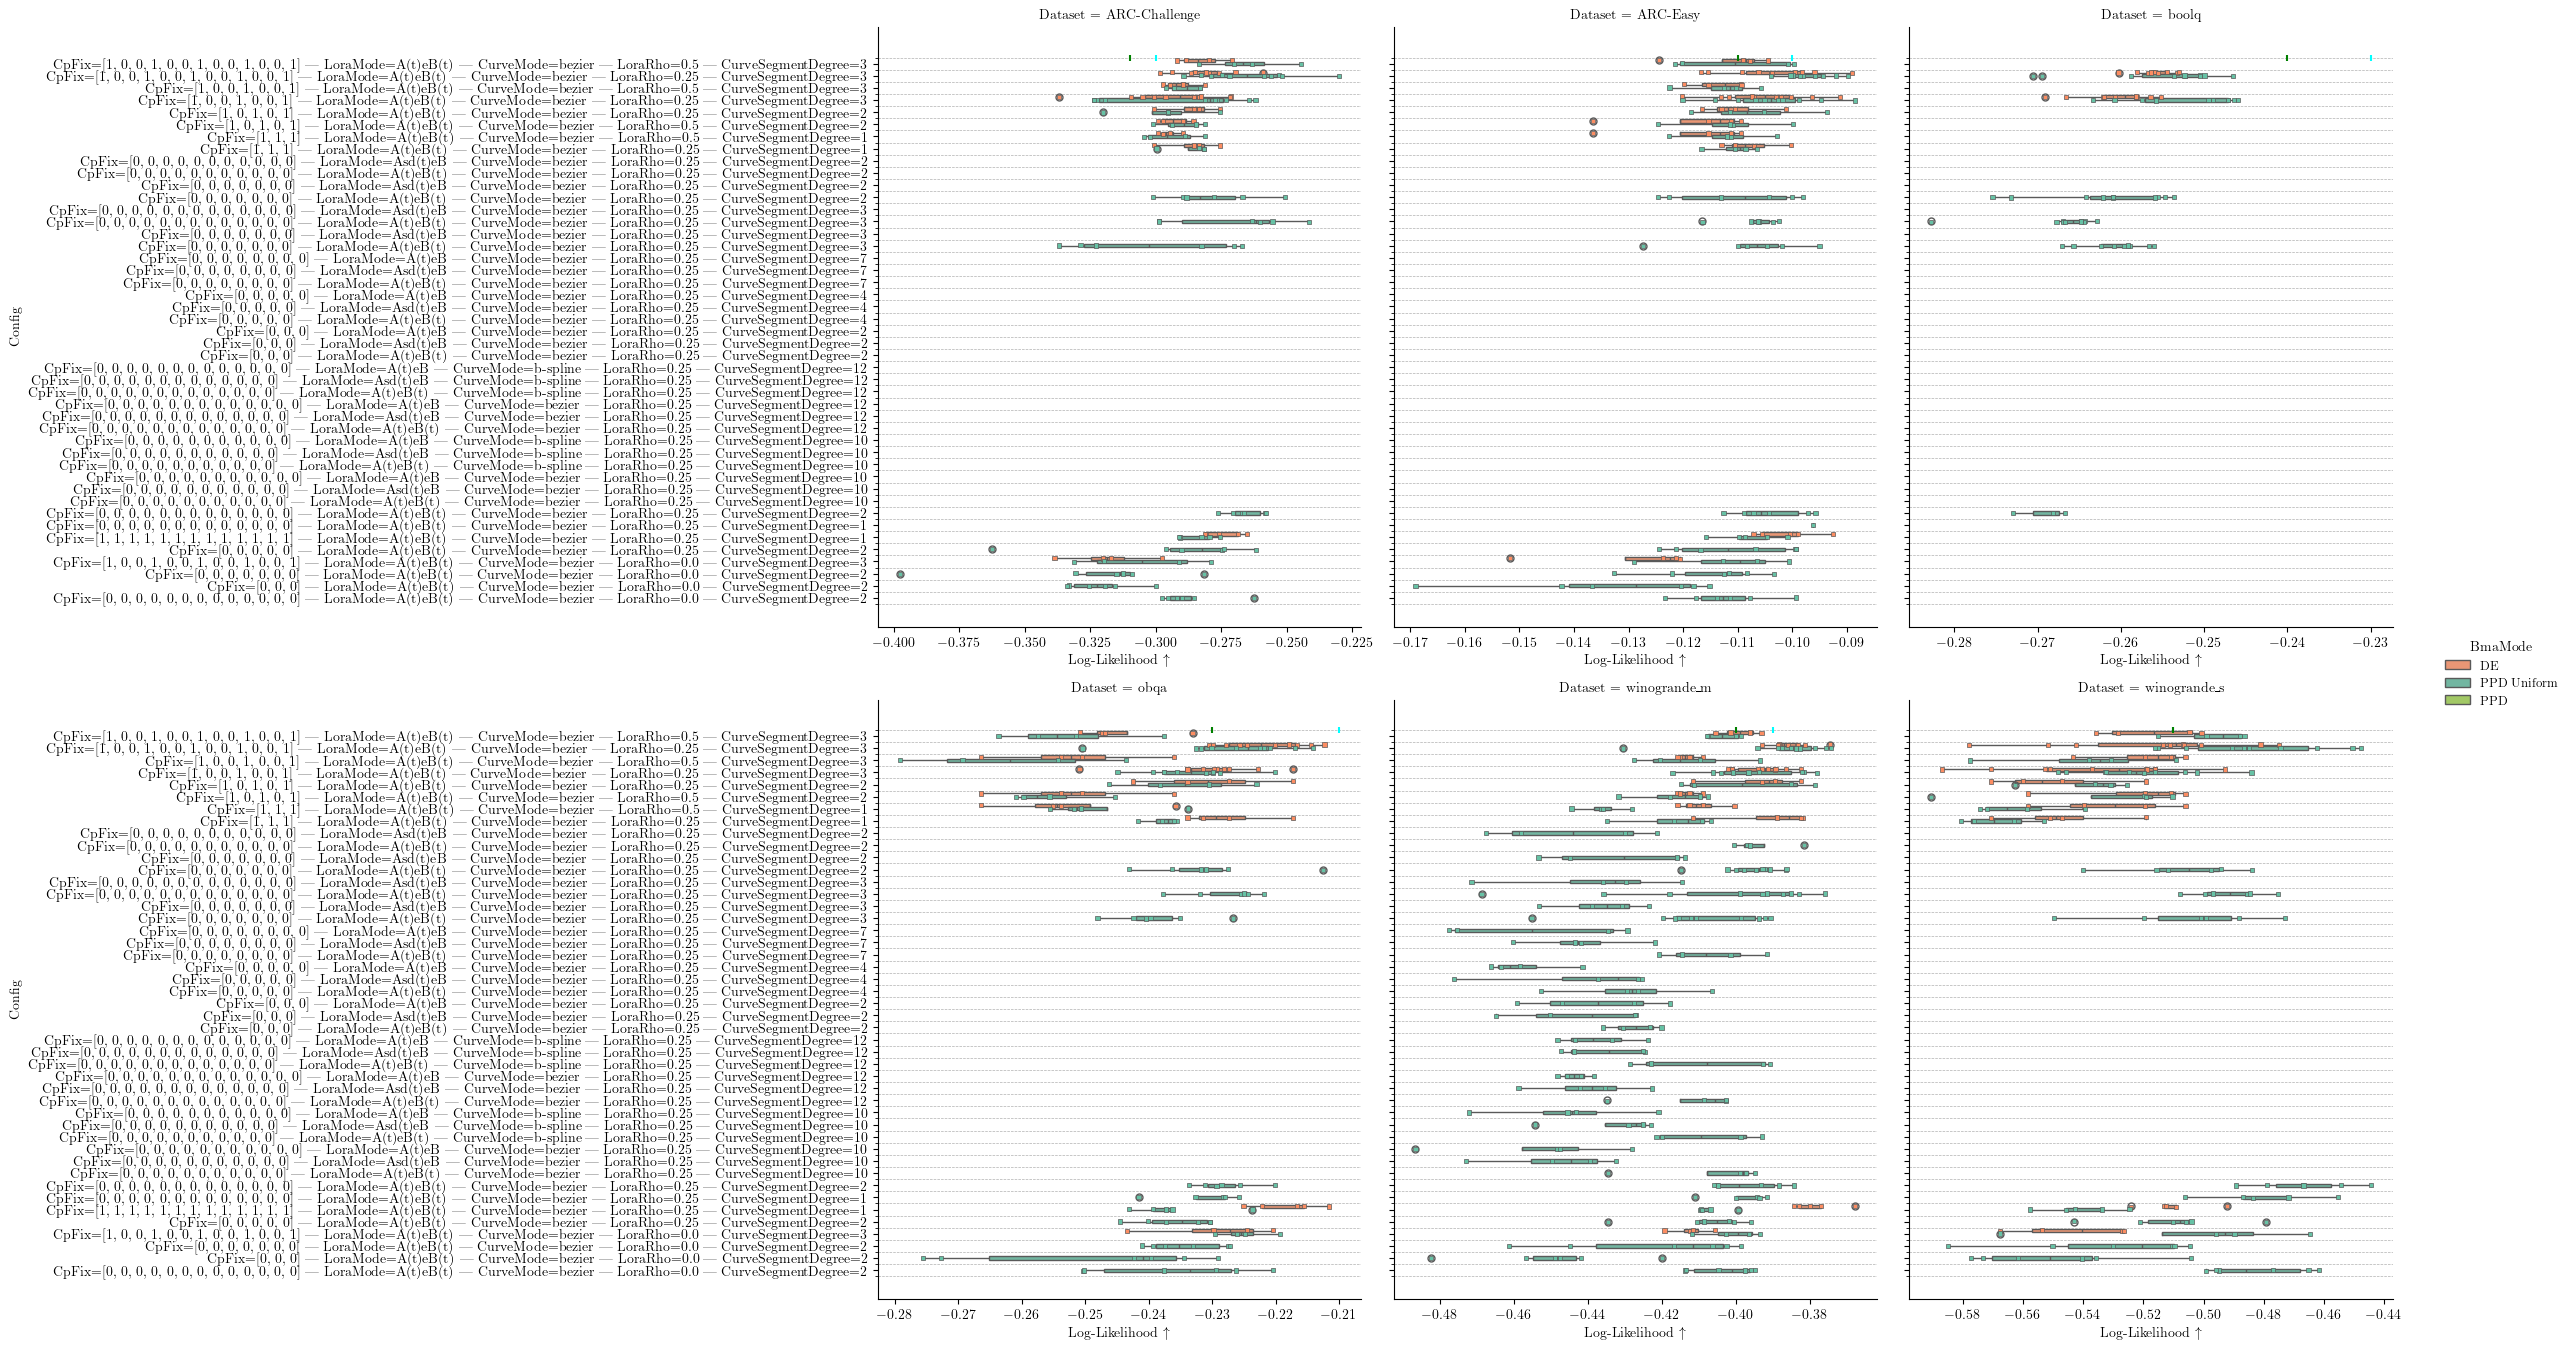

In [14]:
# Filters
df_plot = df_plot[(df_plot['BmaMode'] != 'PPD') & (df_plot['Metric'] == 'll')]

hue_order = ['DE', 'PPD Uniform', 'PPD']
cmap = sns.color_palette("Set2")
hue_palette = {'DE': cmap[1], 'PPD Uniform': cmap[0], 'PPD': cmap[4]}

g = sns.catplot(
    data=df_plot, y='Config', x='value', hue='BmaMode', kind='box',
    col='Dataset', palette=hue_palette, col_wrap=3,
    height=figsize[1] * 2, col_order=col_order,
    hue_order=hue_order, aspect=1.2, sharex=False
)

# Overlay strip plots
for ds, ax in g.axes_dict.items():
    sns.stripplot(
        data=df_plot[df_plot['Dataset'] == ds],
        y='Config', x='value', hue='BmaMode',
        ax=ax, palette=hue_palette, dodge=True,
        edgecolor='gray', linewidth=0.5, size=3, marker='s',
        hue_order=hue_order, legend=False
    )
    ax.set_xlabel(r'Log-Likelihood $\uparrow$')

# Draw reference lines (ll only) - horizontal lines become vertical
ref_dict = ref_nll
transform = lambda v: -v

for ds, ax in g.axes_dict.items():
    if ds in ref_dict:
        tick = -0.5 # Config axis tick
        ax.vlines(x=transform(ref_dict[ds]['BLoB']),    ymin=tick-0.25, ymax=tick+0.25,
                  colors='cyan',  linestyles='--', lw=1.5, label='BLoB')
        ax.vlines(x=transform(ref_dict[ds]['ScalaBL']), ymin=tick-0.25, ymax=tick+0.25,
                  colors='green', linestyles='--', lw=1.5, label='ScalaBL')

# Rotate labels not needed for transposed y-axis usually, but keeping general style
for ax in g.axes.flat:
    # ax.tick_params(axis='y', labelrotation=0)
    pass

g.tight_layout()

# grid lines for y-axis (configs)
for ax in g.axes.flat:
    major_ticks = ax.get_yticks()
    if len(major_ticks) > 0:
        minor_ticks = np.arange(start=min(major_ticks) - 0.5, 
                                stop=max(major_ticks) + 1.5, 
                                step=1)
        ax.set_yticks(minor_ticks, minor=True)
        ax.grid(True, axis='y', which='minor', linestyle='--', linewidth=0.5)

/tmp/ipykernel_888869/2042315865.py:31: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_888869/2042315865.py:31: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_888869/2042315865.py:31: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_888869/2042315865.py:31: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_888869/2042315865.py:31: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_888869/2042315865.py:31: FutureWarning: Use "auto" to set automatic grayscale colors.

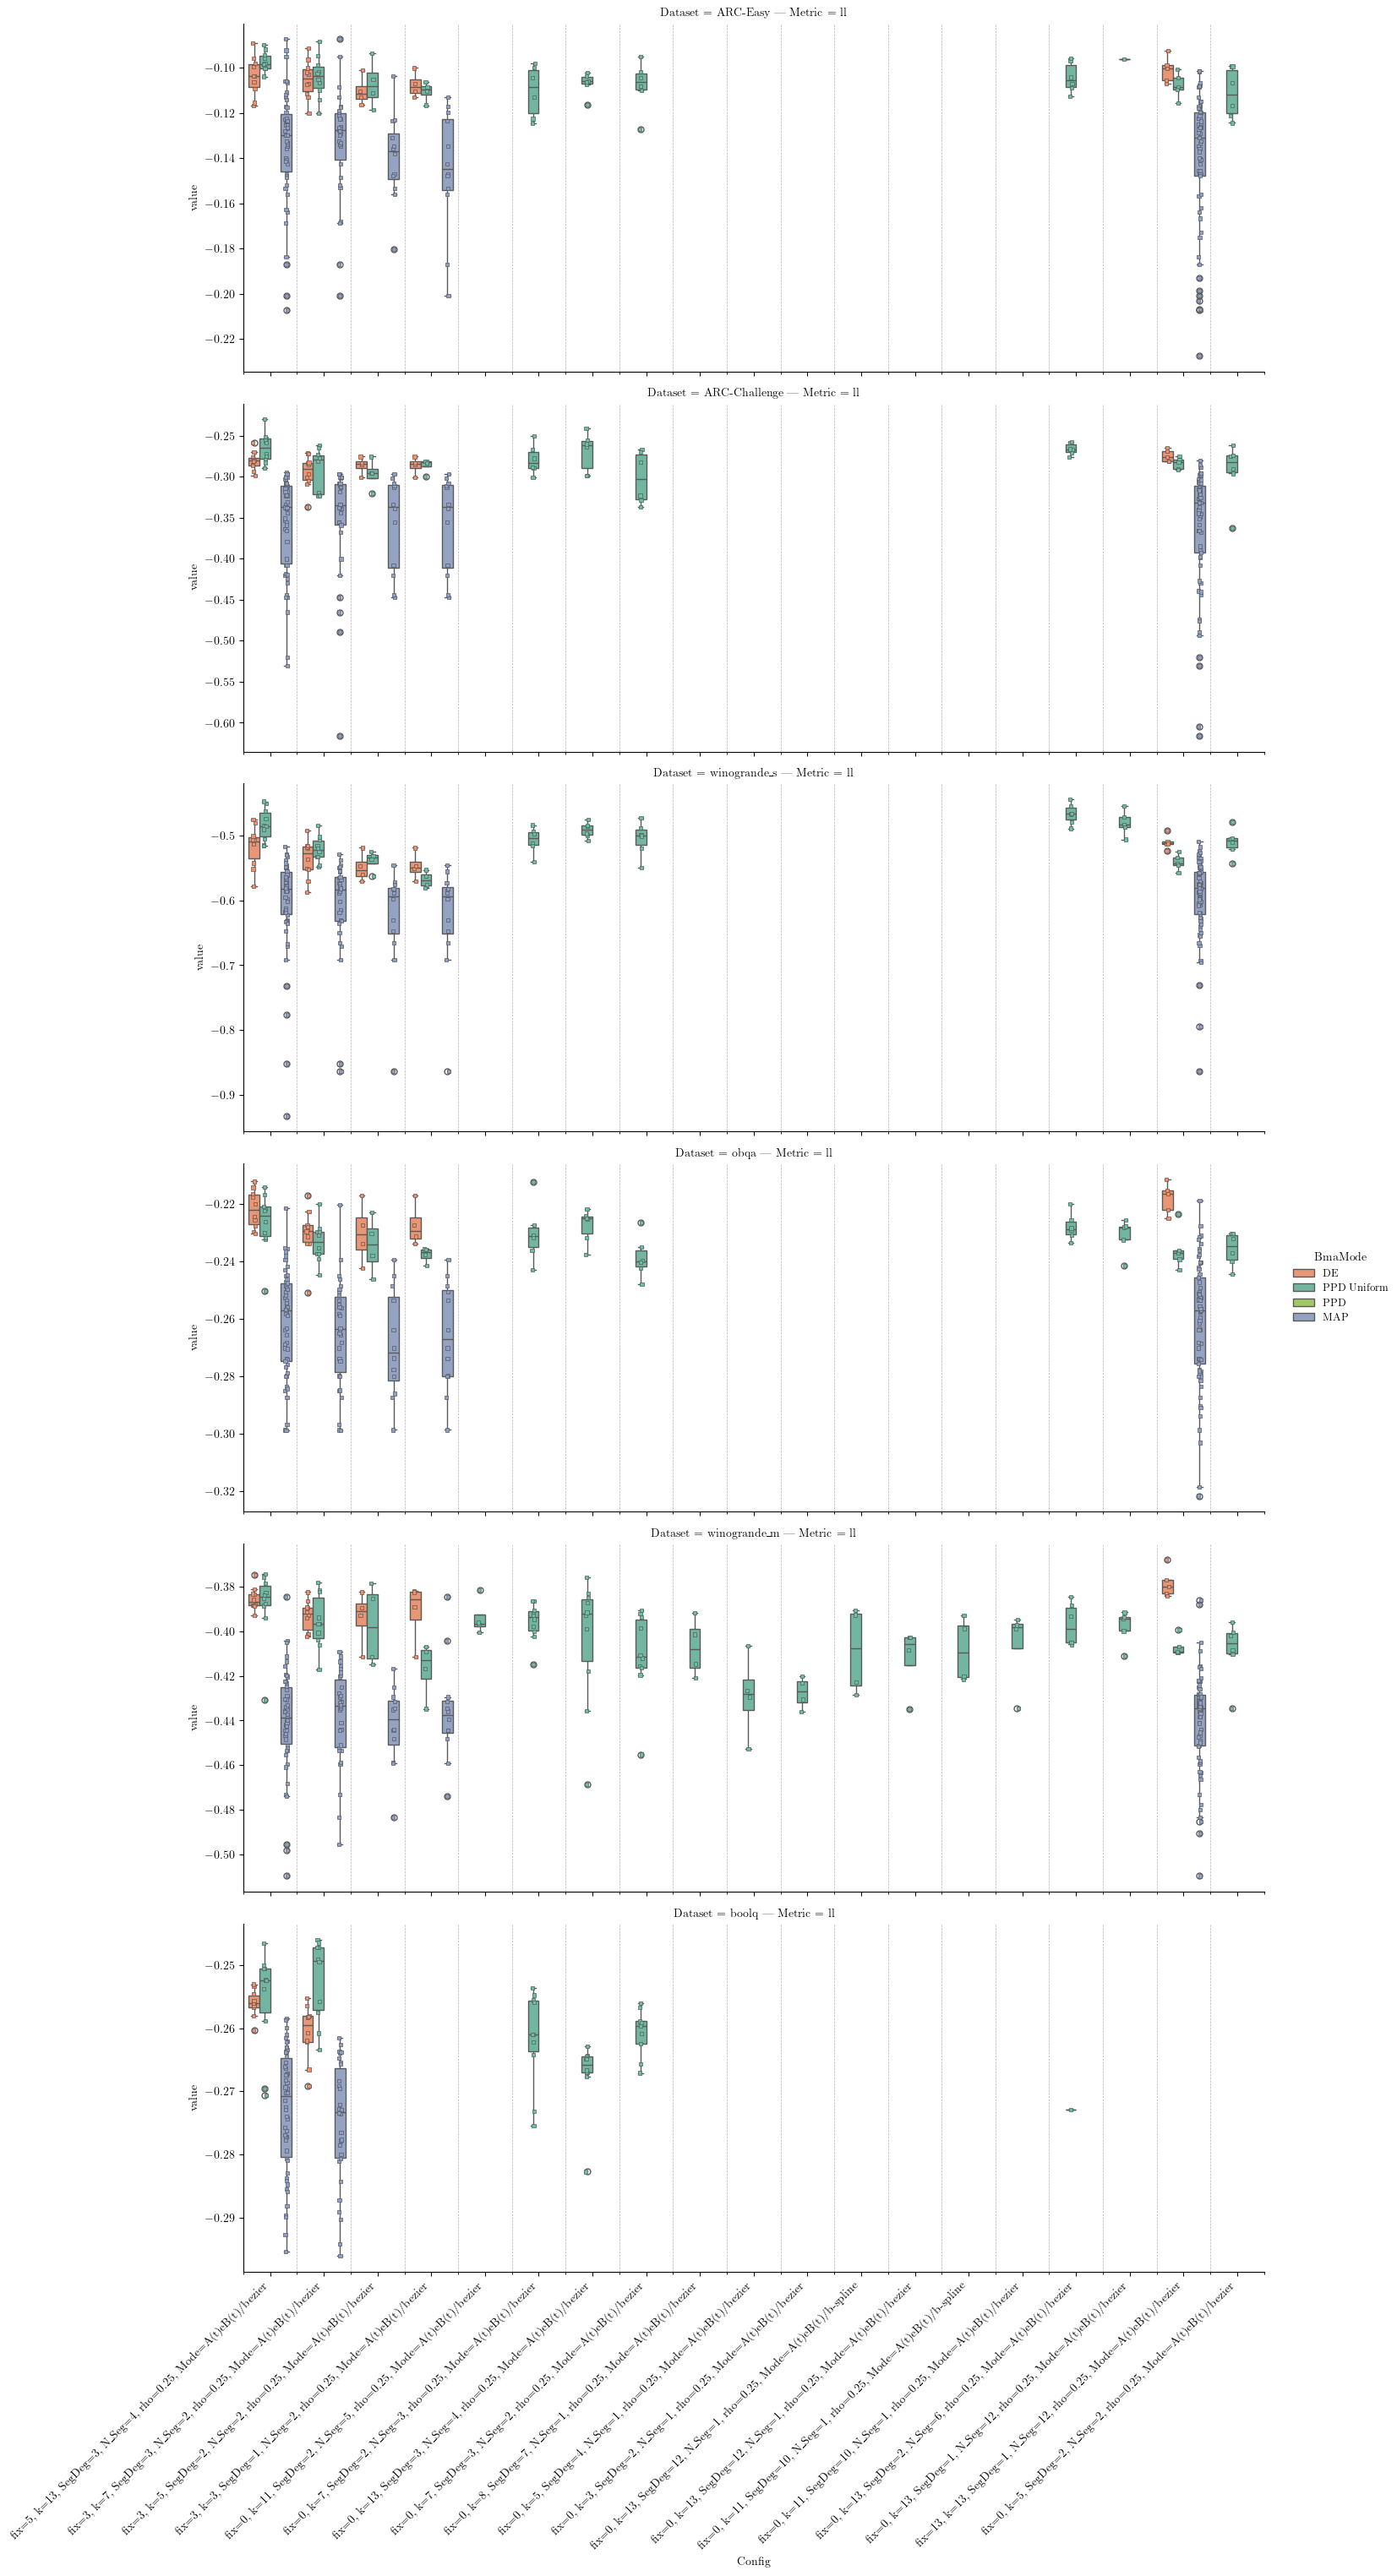

In [158]:
# DE vs Curve
# Build Config label
df_subset = df_clean.copy()
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: f"fix={r['NumPretrained']}, k={r['CurveSpace']}, SegDeg={r['CurveSegmentDegree']}, N_Seg={r['NCurveSegment']}, rho={r['LoraRho']}, Mode={r['LoraMode']}/{r['CurveMode']}", axis=1)

# Melt to long form: acc, ll, ece → Metric + value
# id_cols = [c for c in df_subset.columns if c not in ('acc', 'll', 'ece')]
# df_plot = df_subset.melt(id_vars=id_cols, value_vars=['acc', 'll', 'ece'], var_name='Metric', value_name='value')
df_plot = df_plot[(df_plot['BmaMode'] != 'PPD') & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['Dataset'] == "winogrande_m") & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
df_plot = df_plot[(df_plot['LoraRho'] == 0.25)]

# hue_order = df_plot['BmaMode'].unique()
hue_order = ['DE', 'PPD Uniform', 'PPD', 'MAP']
# Single color for all hue levels
cmap = sns.color_palette("Set2")
hue_palette = {'DE': cmap[1], 'PPD Uniform': cmap[0], 'PPD': cmap[4], 'MAP': cmap[2]}

metric_order = ['acc', 'll', 'ece']

g = sns.catplot(
    data=df_plot, x='Config', y='value', hue='BmaMode', kind='box',
    row='Dataset', col='Metric', palette=hue_palette, sharey=False,
    height=figsize[1] * 1.5,
    hue_order=hue_order, aspect=3
)

# Overlay strip plots
for (ds, metric), ax in g.axes_dict.items():
    sns.stripplot(
        data=df_plot[(df_plot['Dataset'] == ds) & (df_plot['Metric'] == metric)],
        x='Config', y='value', hue='BmaMode',
        ax=ax, palette=hue_palette, dodge=True,
        edgecolor='gray', linewidth=0.5, size=3, marker='s',
        hue_order=hue_order, legend=False
    )

# # Set y-axis labels per metric column
# ylabel_map = {'acc': r'ACC $\uparrow$', 'll': r'Log-Likelihood $\uparrow$', 'ece': r'ECE $\downarrow$'}
# for col_idx, metric in enumerate(metric_order):
#     for ax in g.axes[:, col_idx]:
#         ax.set_ylabel(ylabel_map[metric])


# Rotate x-tick labels on last row
for ax in g.axes[-1, :].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

g.tight_layout()

# make grid (only lines for y-axis) but at +- 0.5pt
major_ticks = ax.get_xticks()
minor_ticks = np.arange(start=min(major_ticks) - 0.5, 
                        stop=max(major_ticks) + 1.5, 
                        step=1)
# Set these positions as minor ticks
ax.set_xticks(minor_ticks, minor=True)
for ax in g.axes.flat:
    ax.grid(True, axis='x', which='minor', linestyle='--', linewidth=0.5,)


#### final summary

In [7]:
df_subset = df_clean.copy()
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode']]), axis=1)


df_plot = df_plot[(df_plot['BmaMode'] != 'PPD') & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['Dataset'] == "winogrande_m") & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
df_plot = df_plot[(df_plot['LoraRho'] == 0.25)]
df_plot = df_plot[df_plot['Metric'].isin(["ll", "acc", "ece"])]


def map_model(x):
    if x['BmaMode'] == 'MAP':
        return "MAP"
    elif x['BmaMode'] == 'DE':
        return f"DE({x['NumPretrained']})"
    elif x['BmaMode'] == 'PPD Uniform':
        is_fixed = np.sum(x['NumPretrained']) > 0
        seg_deg = x['CurveSegmentDegree']
        curve_space = int(x['CurveSpace'])
        
        if seg_deg == 1:
            prefix = "Linear" if is_fixed else "OpenLinear"
            return f"{prefix}({curve_space})"
        else:
            return f"Fix={is_fixed}, N_Seg={x['NCurveSegment']}, SegDeg={seg_deg}"

df_plot['Model'] = df_plot.apply(map_model, axis=1)
# set NCurveSegment to 0 for MAP and DE
df_plot.loc[df_plot['BmaMode'] == 'MAP', 'NCurveSegment'] = 0
df_plot.loc[df_plot['BmaMode'] == 'DE', 'NCurveSegment'] = 0

df_plot.sort_values(by=['Model'], inplace=True)

# df_plot['NCurveSegment'] = pd.Categorical(df_plot['NCurveSegment'], categories=sorted(df_plot['NCurveSegment'].unique()), ordered=True)

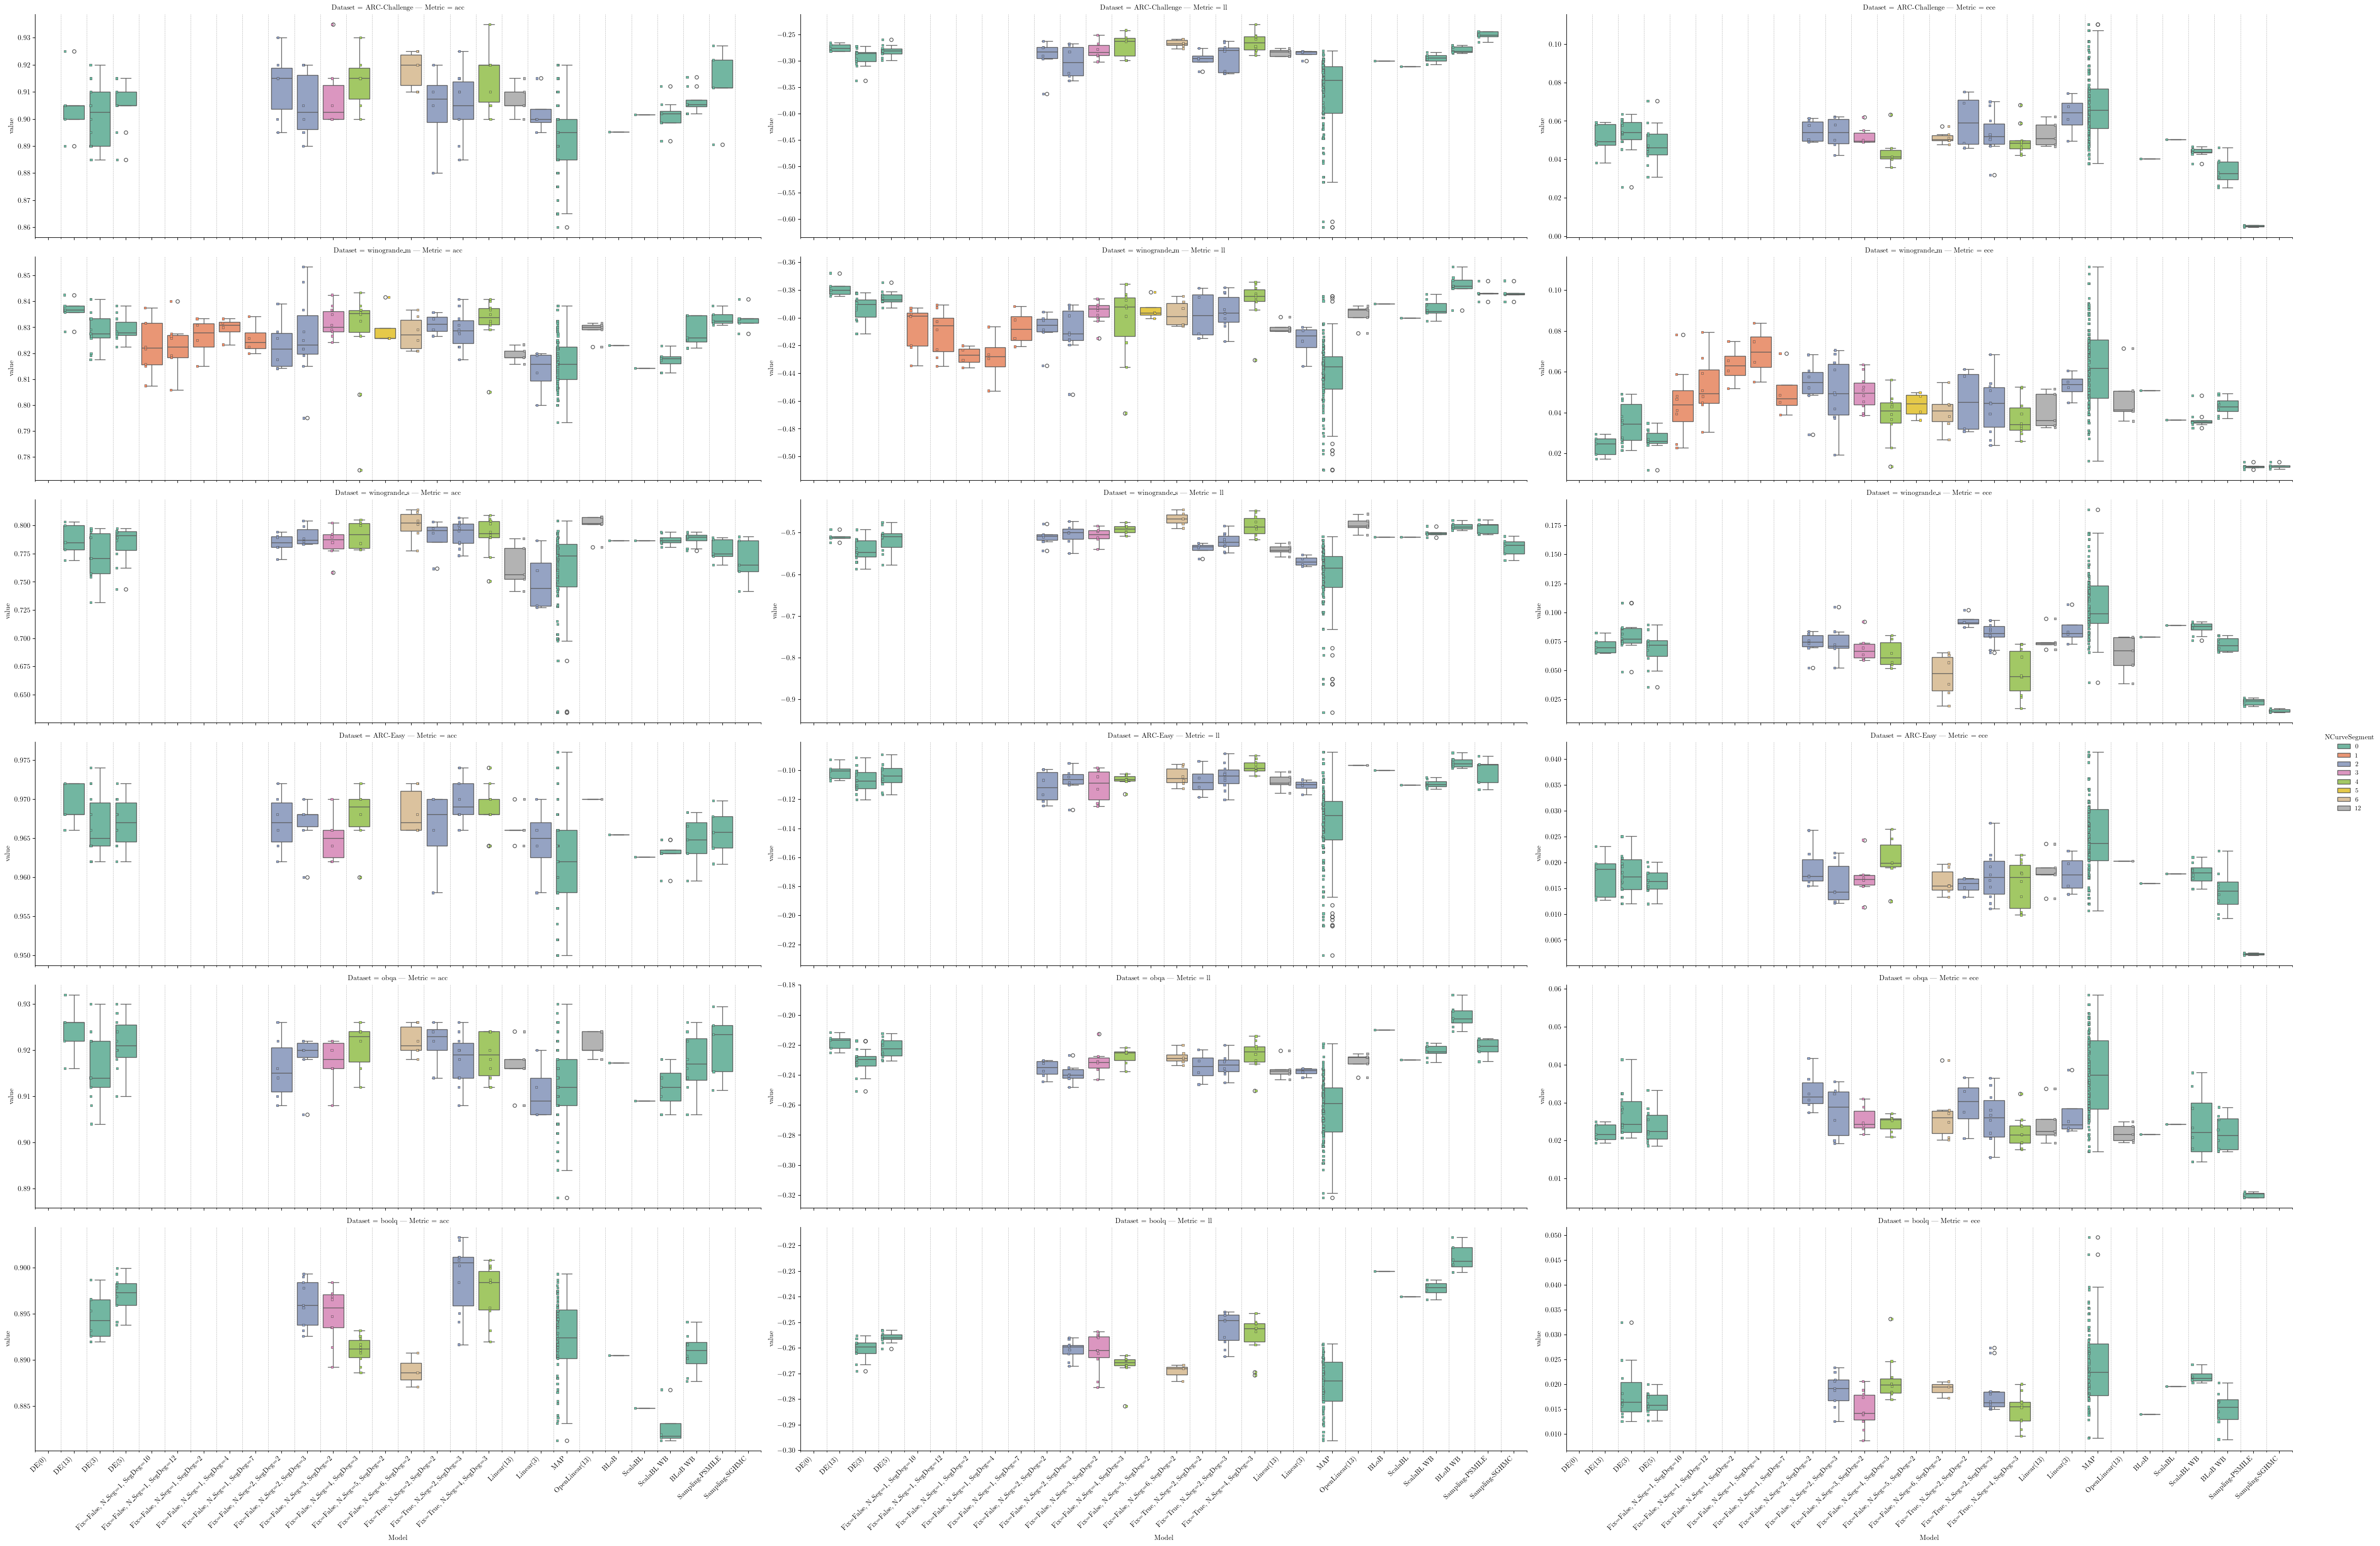

In [8]:
# stack df_vi to df_plot
df_plot['NCurveSegment'] = df_plot['NCurveSegment'].astype(int)
df_plot_ = pd.concat([df_plot, df_vi_paper, df_vi, df_sampling], ignore_index=True)
df_plot_['Model'] = df_plot_.apply(lambda m: f"Linear({int(m['CurveSpace'])})" if m['Model'].endswith("SegDeg=1") and m['Model'].startswith("Fix=True") else m['Model'], axis=1)
df_plot_['Model'] = df_plot_.apply(lambda m: f"OpenLinear({int(m['CurveSpace'])})" if m['Model'].endswith("SegDeg=1") and m['Model'].startswith("Fix=False") else m['Model'], axis=1)


numeric_rhos = sorted(int(x) for x in df_plot_['NCurveSegment'].unique())
df_plot_['NCurveSegment'] = df_plot_['NCurveSegment'].astype(str)
hue_order = [str(x) for x in numeric_rhos]

hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))


g = sns.catplot(
    data=df_plot_, x='Model', y='value', hue='NCurveSegment', kind='box',
    row='Dataset', col='Metric', palette=hue_palette, sharey=False,
    height=figsize[1] * 1.5,
    hue_order=hue_order, aspect=3
)

# Overlay strip plots
for (ds, metric), ax in g.axes_dict.items():
    sns.stripplot(
        data=df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)],
        x='Model', y='value', hue='NCurveSegment',
        ax=ax, palette=hue_palette, dodge=True,
        edgecolor='auto', linewidth=0.5, size=3, marker='s',
        hue_order=hue_order, legend=False
    )

# # Set y-axis labels per metric column
# ylabel_map = {'acc': r'ACC $\uparrow$', 'll': r'Log-Likelihood $\uparrow$', 'ece': r'ECE $\downarrow$'}
# for col_idx, metric in enumerate(metric_order):
#     for ax in g.axes[:, col_idx]:
#         ax.set_ylabel(ylabel_map[metric])


# Rotate x-tick labels on last row
for ax in g.axes[-1, :].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')

g.tight_layout()

# make grid (only lines for y-axis) but at +- 0.5pt
major_ticks = ax.get_xticks()
minor_ticks = np.arange(start=min(major_ticks) - 0.5, 
                        stop=max(major_ticks) + 1.5, 
                        step=1)
# Set these positions as minor ticks
ax.set_xticks(minor_ticks, minor=True)
for ax in g.axes.flat:
    ax.grid(True, axis='x', which='minor', linestyle='--', linewidth=0.5,)

plt.savefig("result/performance.png", dpi=300)
plt.savefig("result/performance.pdf", dpi=300)


Models {'DE(0)'} missing:


/tmp/ipykernel_893322/2183794172.py:50: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


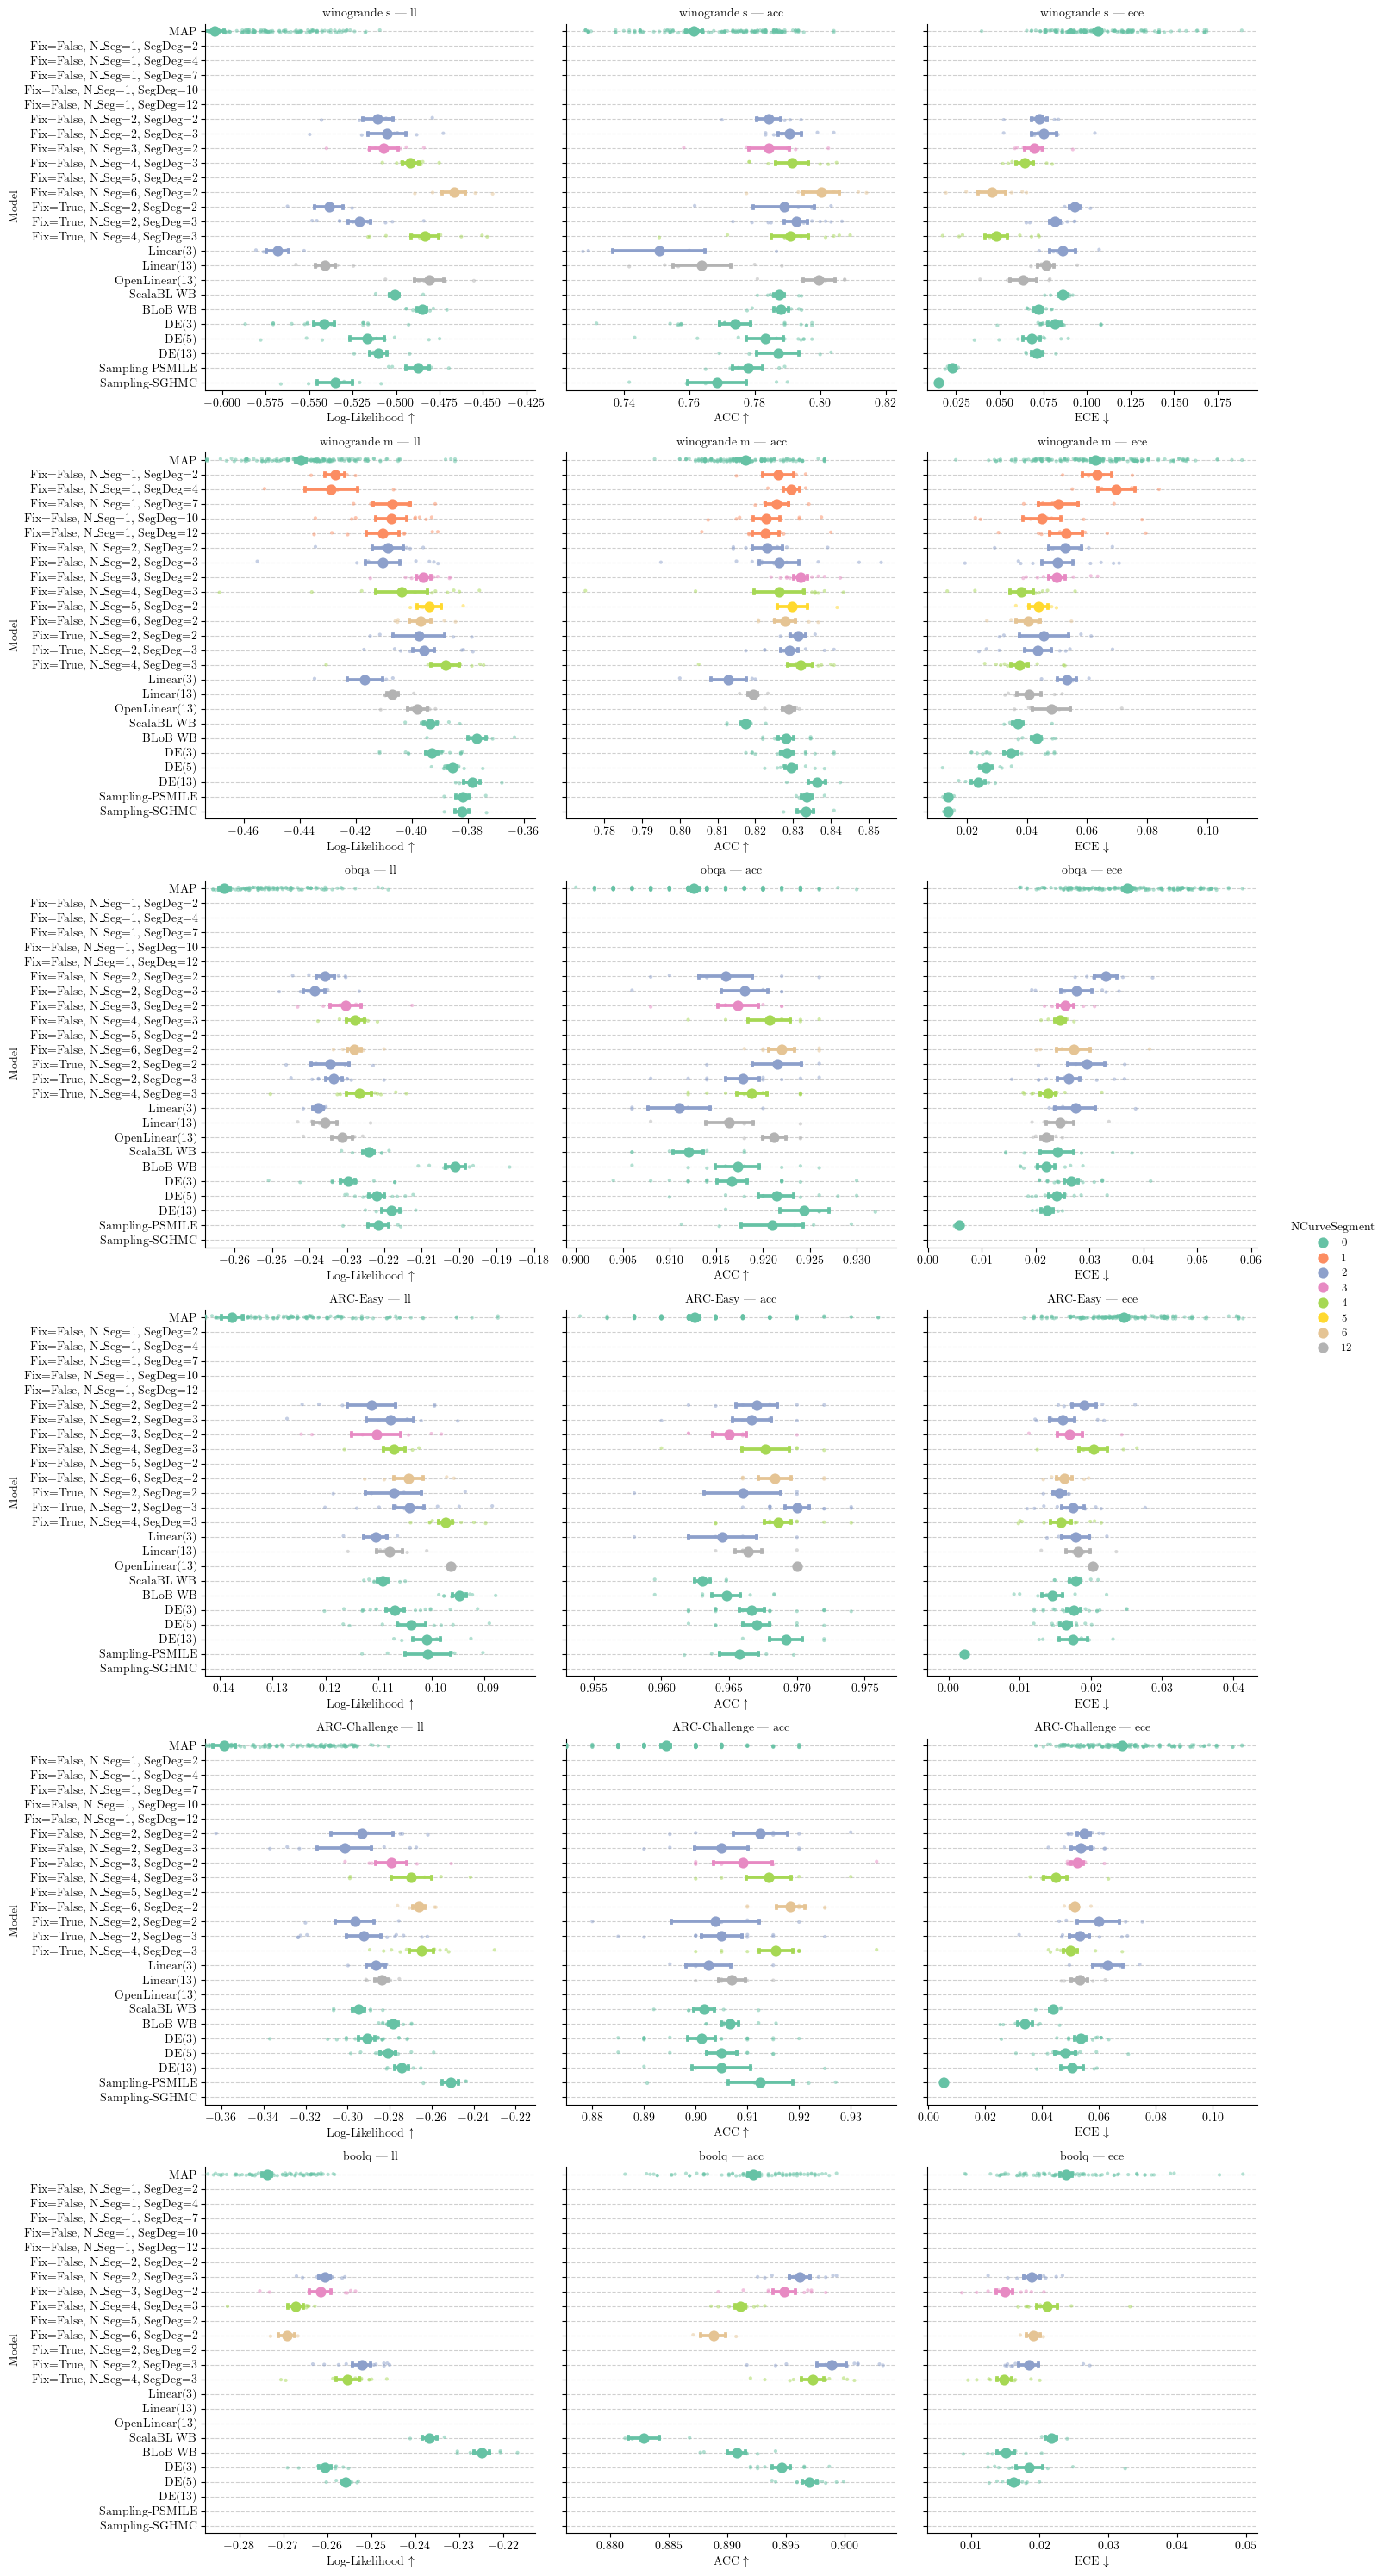

In [9]:
# stack df_vi to df_plot
df_plot['NCurveSegment'] = df_plot['NCurveSegment'].astype(int)
df_plot_ = pd.concat([df_plot, df_vi, df_sampling], ignore_index=True)
# hue
numeric_rhos = sorted(int(x) for x in df_plot_['NCurveSegment'].unique())
df_plot_['NCurveSegment'] = df_plot_['NCurveSegment'].astype(str)
hue_order = [str(x) for x in numeric_rhos]
hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))
col_order = "ll", "acc", "ece"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"
# order = df_plot_['Model'].unique()
order = ['MAP', 
         'Fix=False, N_Seg=1, SegDeg=2',
         'Fix=False, N_Seg=1, SegDeg=4', 
         'Fix=False, N_Seg=1, SegDeg=7',
         'Fix=False, N_Seg=1, SegDeg=10',
         'Fix=False, N_Seg=1, SegDeg=12', 
         'Fix=False, N_Seg=2, SegDeg=2', 
         'Fix=False, N_Seg=2, SegDeg=3', 
         'Fix=False, N_Seg=3, SegDeg=2',
         'Fix=False, N_Seg=4, SegDeg=3', 
         'Fix=False, N_Seg=5, SegDeg=2',
         'Fix=False, N_Seg=6, SegDeg=2', 
        #  'Fix=False, N_Seg=12, SegDeg=1', 
        #  'Fix=True, N_Seg=12, SegDeg=1', 
        #  'Fix=True, N_Seg=2, SegDeg=1',
         'Fix=True, N_Seg=2, SegDeg=2', 
         'Fix=True, N_Seg=2, SegDeg=3',
         'Fix=True, N_Seg=4, SegDeg=3',
         'Linear(3)', 'Linear(13)', 'OpenLinear(13)',
         'ScalaBL WB', 'BLoB WB', 
         'DE(3)', 'DE(5)', 'DE(13)', 
         'Sampling-PSMILE', 'Sampling-SGHMC']

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

# # Prepare descriptive Model labels
# def get_model_label(row):
#     if str(row['Model']).startswith('DE'):
#         return f"{row['Model']}({row['NCurveSegment']})"
#     return f"{row['Model']}"

# df_plot_['Model_Label'] = df_plot_.apply(get_model_label, axis=1)

# # Ensure metric order
# metric_order = ['acc', 'll', 'ece']
# df_plot_['Metric'] = pd.Categorical(df_plot_['Metric'], categories=metric_order, ordered=True)

# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Dataset', col='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue='NCurveSegment',
    dodge=False, sharex=False, height=5, aspect=1.,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for (ds, metric), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=False, hue='NCurveSegment', legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
# g.add_legend(title='#CurveSegments')
plt.savefig("result/performance_pointplot.png", dpi=300)
plt.savefig("result/performance_pointplot.pdf", dpi=300)
plt.show()

#### Linear Mode connect

/tmp/ipykernel_876860/3102950494.py:24: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


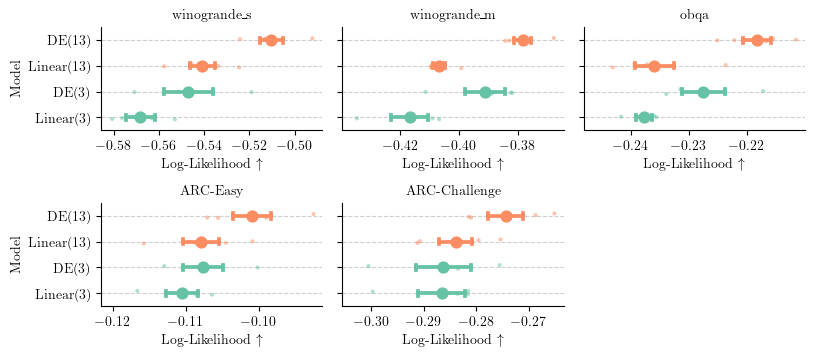

In [18]:
# Filter for linear mode connected curves (SegDeg=1) or baseline models
# baseline models typically have SegDeg=nan or 0 depending on data processing
# Using df_plot_ from the previous cell
df_linear = df_plot_[df_plot_['Model'].isin(['DE(3)', 'Linear(3)', 'DE(13)', 'Linear(13)'])].copy()
df_linear = df_linear[df_linear['CurveSpace'].isin([3., 13.])]

# Filter for only Log-Likelihood (ll)
df_linear = df_linear[df_linear['Metric'] == 'll'].copy()

# hue
numeric_rhos = sorted(int(x) for x in df_linear['CurveSpace'].unique())
df_linear_plot = df_linear.copy()
df_linear_plot['CurveSpace'] = df_linear_plot['CurveSpace'].astype(int).astype(str)
hue_order = [str(x) for x in numeric_rhos]
hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))
# col_order = "ll", "acc", "ece" # Not needed as we only have 'll'
row_order = None # We want different datasets in columns/rows with col_wrap
# dataset_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"
col_order = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"]
col_order = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge",]
order = "DE(13)", "Linear(13)", "DE(3)", "Linear(3)"

# Seaborn Catplot (ANOVA style) for Linear Mode Connected Curves
g = sns.catplot(
    data=df_linear_plot, x='value', y='Model',
    col='Dataset', col_wrap=3,
    order=order, col_order=col_order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue='CurveSpace',
    dodge=False, sharex=False, height=figsize[0]/3, aspect=1.5,
    legend=False, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots
# Note: axes_dict items will be (dataset_name,) when using col='Dataset'
for ds, ax in g.axes_dict.items():
    subset = df_linear_plot[df_linear_plot['Dataset'] == ds]
    if subset.empty:
        continue
        
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=False, hue='CurveSpace', legend=False, hue_order=hue_order,
    )
    
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # Since we only show ll, label it appropriately
    ax.set_xlabel(r'Log-Likelihood $\uparrow$')

    # clip x-axis
    def only_finit(x):
        return x[np.isfinite(x)]
    
    vals_no_map = subset[subset['Model'] != 'MAP']['value']
    vals_map = subset[subset['Model'] == 'MAP']['value']
    
    f_no_map = only_finit(vals_no_map)
    f_map = only_finit(vals_map)
    
    if not f_no_map.empty or not f_map.empty:
        min_v = f_no_map.min() if not f_no_map.empty else f_map.min()
        mean_map = f_map.mean() if not f_map.empty else f_no_map.min()
        ax.set_xlim(left=min(min_v, mean_map)-0.005)

g.set_titles(col_template='{col_name}')
# plt.suptitle("Linear Mode Connected Curves (SegDeg=1) - Log Likelihood", y=1.02)
g.tight_layout()
plt.savefig("result/performance_linear_curves_ll" + ".jpeg",
        format='jpeg',            # Use JPEG instead of PNG
        dpi=60,                   # Lower resolution (80-100 is usually plenty)
        bbox_inches='tight',      # Remove empty whitespace
        pil_kwargs={'quality': 50} # Tell PIL to compress the JPEG (0-100)
    )
plt.savefig("result/performance_linear_curves_ll.pdf", dpi=300)

In [22]:
import os
import logging
import wandb
import numpy as np
from scipy.special import logsumexp
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path

def plot_combined_datasets_for_cp_fix(project_path="ddold/qwen_PtoC_seg", target_cp_fix=[1, 1, 1]):
    """
    Fetches runs from W&B, filters for a specific cp_fix, and combine datasets into one plot
    using seaborn relplot with lineplot.
    """
    api = wandb.Api()
    print(f"Fetching runs from {project_path}...")
    
    runs = api.runs(project_path)
    download_dir = Path("tmp_artifacts")
    download_dir.mkdir(exist_ok=True)
    
    KNOWN_DATASETS = ["winogrande_s", "winogrande_m", "ARC-Challenge", "ARC-Easy", "obqa", "boolq"]
    def get_dataset_name(ds_path):
        for kd in KNOWN_DATASETS:
            if kd in ds_path: return kd
        return Path(ds_path).stem

    # We will collect everything into a list of dictionaries to build a DataFrame
    records = []

    for run in runs:
        if hasattr(run, "tags") and run.tags and any("hide" in str(tag).lower() for tag in run.tags):
            continue
        if hasattr(run, "sweep") and run.sweep is None:
            continue
            
        cfg = run.config.get("model_params", {})
        cp_fix = cfg.get("cp_fix", [])
        if cp_fix != target_cp_fix:
            continue
            
        data_cfg = run.config.get("data", {})
        ds_path = data_cfg.get("dataset_path", "")
        if not ds_path:
            continue
            
        dataset_name = get_dataset_name(ds_path)
        print(f"Processing run: {run.name} | Dataset: {dataset_name}")
        
        artifacts = list(run.logged_artifacts())
        logits_artifact = next((a for a in artifacts if "logits" in a.name and a.type == "npz"), None)
        if not logits_artifact:
            continue
            
        art_dir = download_dir / run.id
        logits_artifact.download(root=str(art_dir))
        
        seg_deg = cfg.get("curve_segment", False) or 1
        n_seg = (len(cp_fix) - 1) // seg_deg
        max_t = float(n_seg)
        
        # Load both train and test/val
        for split in ["train", "test"]:
            file_path = list(art_dir.glob(f"*{split}_logits.npz"))
            if not file_path and split == "test":
                file_path = list(art_dir.glob("*val_logits.npz"))
            if not file_path:
                continue
                
            npz = np.load(file_path[0])
            logits = npz["logits"]
            labels = npz["labels"]
            
            n_t = logits.shape[0]
            t_space = np.linspace(0, max_t, n_t)
            
            log_probs = logits - logsumexp(logits, axis=-1, keepdims=True)
            true_log_probs = log_probs[:, np.arange(len(labels)), labels]
            ll_list = np.mean(true_log_probs, axis=1)
            
            # Store absolute LL point by point for pandas manipulation
            for t_val, ll_val in zip(t_space, ll_list):
                records.append({
                    "Dataset": dataset_name,
                    "Split": split,
                    "t": t_val,
                    "LL": ll_val,
                    "Run_ID": run.id
                })

    if not records:
        print(f"No run found with cp_fix == {target_cp_fix}")
        return

    df = pd.DataFrame(records)

    # 1. Compute the mean LL per dataset and split at exactly t=0
    # Floating point comparisons can be tricky, using np.isclose for safety.
    df_t0 = df[np.isclose(df['t'], 0.0)]
    t0_means = df_t0.groupby(['Dataset', 'Split'])['LL'].mean().reset_index()
    t0_means = t0_means.rename(columns={'LL': 't0_mean_LL'})

    # 2. Merge these means back into the main dataframe
    df = df.merge(t0_means, on=['Dataset', 'Split'], how='left')

    # 3. Calculate the relative LL compared to the dataset/split mean at t=0
    df['Relative_LL'] = df['LL'] - df['t0_mean_LL']
    
    # 4. Define custom palette and order using *only* Set2 colors
    hue_order = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge",]
    # hue_order = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"]
    set2 = sns.color_palette("Set2")
    custom_palette = {
        "winogrande_m": set2[0],   # dark green/teal
        "winogrande_s": set2[4],   # light green
        "obqa": set2[2],           # blue
        "ARC-Challenge": set2[1],  # orange
        "ARC-Easy": set2[3],       # red/pink
        "boolq": set2[7]           # grey
    }

    # Use seaborn relplot to create the facet grid lineplot for mean lines first
    g = sns.relplot(
        data=df,
        x="t",
        y="Relative_LL",
        hue="Dataset",
        hue_order=hue_order,
        col="Split",
        kind="line",
        estimator="mean",      # Mean lines
        errorbar=None,
        height=figsize[0] / 2,
        aspect=1.2,
        linewidth=3.0,         
        palette=custom_palette
    )

    # Now overlay the individual runs logic onto the existing axes
    for ax, split_name in zip(g.axes.flatten(), ["train", "test"]):
        split_data = df[df['Split'] == split_name]
        if split_data.empty: continue
        
        # We manually plot the individual lines via standard sns.lineplot with thinner transparency
        sns.lineplot(
            data=split_data, 
            x="t", 
            y="Relative_LL", 
            hue="Dataset",
            hue_order=hue_order,
            ax=ax, 
            units="Run_ID",
            estimator=None,     
            linewidth=1.0,
            alpha=0.25,
            legend=False,      # Legend already exists from relplot
            palette=custom_palette
        )

    g.set_axis_labels("t (Curve Position)", r"$\Delta$ LL = LL(t) - mean LL(t=0)")
    
    # Add grids
    for ax in g.axes.flatten():
        # ax.grid(True, linestyle="--", alpha=0.6)
        ax.set_ylim(-0.15, 0.15)

    g.tight_layout()
    plt.savefig("result/LinearModeConnect_Losslandscape.pdf", dpi=300, bbox_inches='tight')

# Run the function
plot_combined_datasets_for_cp_fix(target_cp_fix=[1, 1, 1])

fns49u4k: 100%|██████████| 60/60 [00:00<00:00, 299.83it/s, celestial-sweep-1] 
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subt

fns49u4k: 100%|██████████| 60/60 [00:00<00:00, 299.83it/s, celestial-sweep-1] 
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subt

,count,mean,std,min,25%,50%,75%,max
CurveSpace,588.0,1.091837e+01,2.858408e+00,7.000000e+00,7.000000e+00,13.000000,13.000000,13.000000
NumPretrained,588.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000
Jitter,588.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000
Seed,588.0,1.168869e+04,2.034760e+04,1.000000e+00,2.000000e+00,40.000000,16000.000000,64000.000000
WeightDecay,588.0,1.000000e-03,2.170251e-19,1.000000e-03,1.000000e-03,0.001000,0.001000,0.001000
DS_WindowSize,588.0,-2.346939e-01,1.801765e+00,-1.000000e+00,-1.000000e+00,-1.000000,-1.000000,4.000000
EntropyMaxScale,588.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000
NumSteps,588.0,1.000000e+04,0.000000e+00,1.000000e+04,1.000000e+04,10000.000000,10000.000000,10000.000000
LoraRank,588.0,8.000000e+00,0.000000e+00,8.000000e+00,8.000000e+00,8.000000,8.000000,8.000000
Gravity,588.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000


#### Flat Lora Compare

In [52]:
# Build Config label
df_subset = df_clean.copy()
df_subset = df_subset[(df_subset['LoraMode'] == "A(t)eB(t)") & (df_subset['BmaMode'] != 'MAP')]

df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
# df_plot['Config'] = df_plot.apply(lambda r: f"fix={r['NumPretrained']}, k={r['CurveSpace']}, SegDeg={r['CurveSegmentDegree']}, N_Seg={r['NCurveSegment']}, rho={r['LoraRho']}, Mode={r['LoraMode']}/{r['CurveMode']}", axis=1)
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode',]]), axis=1)

col_order = df_subset['Dataset'].unique()
col_order.sort()

df_plot.groupby(variable_idx + ['Metric', 'Seed']).count()


Id  \
CurveSpace CpFix                                   NumPretrained Dataset       BmaMode     LoraMode  CurveMode LoraRho CurveSegmentDegree NCurveSegment Metric                       Seed        
3          [0, 0, 0]                               0             ARC-Challenge DE          A(t)eB(t) bezier    0.00    2                  1             acc                          2       1   
                                                                                                                                                                                     40      1   
                                                                                                                                                                                     800     1   
                                                                                                                                                                                     16000   1   
                                                                                                                                                                                     32000   1   
...                                                                                                                                                                                         ..   
13         [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1] 13            winogrande_s  PPD Uniform A(t)eB(t) bezier    0.25    1                  12            test_std_entropy_along_curve 1       1   
                                                                                                                                                                                     2       1   
                                                                                                                                                                                     20      1   
                                                                                                                                                                                     400     1   
                                                                                                                                                                                     8000    1   

                                                                                                                                                                                            Jitter  \
CurveSpace CpFix                                   NumPretrained Dataset       BmaMode     LoraMode  CurveMode LoraRho CurveSegmentDegree NCurveSegment Metric                       Seed            
3          [0, 0, 0]                               0             ARC-Challenge DE          A(t)eB(t) bezier    0.00    2                  1             acc                          2           1   
                                                                                                                                                                                     40          1   
                                                                                                                                                                                     800         1   
                                                                                                                                                                                     16000       1   
                                                                                                                                                                                     32000       1   
...                                                                                                                                                                                            ...   
13         [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1] 13            winogrande_s  PP

In [60]:
filter_mask = df_subset[df_subset['LoraRho'] == 0.][variable_idx+['Seed',]]
filter_mask

,CurveSpace,CpFix,NumPretrained,Dataset,BmaMode,LoraMode,CurveMode,LoraRho,CurveSegmentDegree,NCurveSegment,Seed
2098,13,"[1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]",5,ARC-Easy,PPD,A(t)eB(t),bezier,0.0,3,4,400
2099,13,"[1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]",5,ARC-Easy,DE,A(t)eB(t),bezier,0.0,3,4,400
2105,13,"[1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]",5,ARC-Easy,PPD Uniform,A(t)eB(t),bezier,0.0,3,4,400
2106,13,"[1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]",5,ARC-Easy,PPD,A(t)eB(t),bezier,0.0,3,4,20
2107,13,"[1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]",5,ARC-Easy,DE,A(t)eB(t),bezier,0.0,3,4,20
...,...,...,...,...,...,...,...,...,...,...,...
3319,13,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,winogrande_m,DE,A(t)eB(t),bezier,0.0,2,6,64000
3320,13,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,winogrande_m,PPD Uniform,A(t)eB(t),bezier,0.0,2,6,64000
3321,13,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,winogrande_m,PPD,A(t)eB(t),bezier,0.0,2,6,800
3322,13,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]",0,winogrande_m,DE,A(t)eB(t),bezier,0.0,2,6,800


In [54]:
df_test_g = df_plot.groupby(variable_idx + ['Metric', 'Seed',])
larger = df_test_g['value'].count() > 1
# df_test[df_test['value'] > 1]
la = df_test_g['value'].apply(list)[larger]
la


Series([], Name: value, dtype: object)

In [45]:
la[0]

/tmp/ipykernel_893322/114084283.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  la[0]


[0.8849999904632568, 0.8700000047683716, 0.9099999666213988]

In [49]:
df_test_g = df[df['BmaMode'] != 'MAP'].groupby(cols)
larger = df_test_g['acc'].count() > 1
# df_test[df_test['value'] > 1]
la = df_test_g['acc'].apply(list)[larger]
la

Series([], Name: acc, dtype: object)

### table

In [50]:
# Generate updated LaTeX table from the latest merged dataframe (df_plot)
from pathlib import Path
import numpy as np
import pandas as pd

if "df_plot" not in globals():
    raise RuntimeError("df_plot not found. Run the merge cell (sampling_scalabl_merge_01) first.")

datasets = ["ARC-Challenge", "ARC-Easy", "obqa", "winogrande_m", "winogrande_s"]
metrics = ["acc", "ece", "ll"]

df_tbl = df_plot.copy()
df_tbl = df_tbl[df_tbl["Metric"].isin(metrics) & df_tbl["Dataset"].isin(datasets)].copy()
df_tbl = df_tbl[np.isfinite(df_tbl["value"])]

grp = df_tbl.groupby(["Metric", "Model", "Dataset"])["value"]
mean = grp.mean()
std2 = 2 * grp.std()

# Keep model order by first appearance in merged dataframe
model_order = []
for m in df_tbl["Model"].tolist():
    if m not in model_order:
        model_order.append(m)

def fmt_plain(m, s):
    if pd.isna(m):
        return "-"
    if pd.isna(s):
        return f"{m:.3f}"
    return f"{m:.3f} $\\pm$ {s:.3f}"

def is_better(metric, candidate, current):
    if pd.isna(current):
        return True
    if metric == "ece":
        return candidate < current
    return candidate > current

best_map = {}
for metric in metrics:
    for ds in datasets:
        best_val = np.nan
        for model in model_order:
            v = mean.get((metric, model, ds), np.nan)
            if pd.isna(v) or not np.isfinite(v):
                continue
            if is_better(metric, v, best_val):
                best_val = v
        best_map[(metric, ds)] = best_val

def mark_text(metric, model, ds):
    m = mean.get((metric, model, ds), np.nan)
    s = std2.get((metric, model, ds), np.nan)
    text = fmt_plain(m, s)
    if text == "-":
        return text

    best_val = best_map.get((metric, ds), np.nan)
    if pd.isna(best_val):
        return text

    if np.isclose(m, best_val, rtol=1e-12, atol=1e-12):
        return f"\\textbf{{\\underline{{{text}}}}}"

    low = m - s if pd.notna(s) else m
    high = m + s if pd.notna(s) else m
    if low <= best_val <= high:
        return f"\\underline{{{text}}}"
    return text

rows = []
for metric in metrics:
    for model in model_order:
        row = {"Metric": metric, "Model": model}
        any_present = False
        for ds in datasets:
            plain = fmt_plain(mean.get((metric, model, ds), np.nan), std2.get((metric, model, ds), np.nan))
            row[ds] = mark_text(metric, model, ds)
            if plain != "-":
                any_present = True
        if any_present:
            rows.append(row)

df_table = pd.DataFrame(rows)
out_csv = "result/performance_table.csv"
df_table.to_csv(out_csv, index=False)

# Build LaTeX table block
def esc(s):
    s = str(s)
    s = s.replace("_", "\\_")
    s = s.replace("&", "\\&")
    s = s.replace("%", "\\%")
    return s

lines = []
lines.append("\\begin{table*}[htbp]")
lines.append("\\centering")
lines.append("\\caption{Updated performance table from the latest merged plot data (mean $\\pm$ 2$\\sigma$ across available seeds/runs). Best per metric/dataset is bold+underlined; models whose mean$\\pm$2$\\sigma$ interval contains the best are underlined.}")
lines.append("\\label{tab:performance_metrics_updated}")
lines.append("\\resizebox{\\textwidth}{!}{%")
lines.append("\\begin{tabular}{llccccc}")
lines.append("\\toprule")
lines.append("\\textbf{Metric} & \\textbf{Model} & \\textbf{ARC-Challenge} & \\textbf{ARC-Easy} & \\textbf{obqa} & \\textbf{winogrande\\_m} & \\textbf{winogrande\\_s} " + r"\\")
lines.append("\\midrule")

for i, r in df_table.iterrows():
    if i > 0 and r["Metric"] != df_table.iloc[i - 1]["Metric"]:
        lines.append("\\midrule")
    lines.append(
        f"{esc(r['Metric'])} & {esc(r['Model'])} & {r['ARC-Challenge']} & {r['ARC-Easy']} & {r['obqa']} & {r['winogrande_m']} & {r['winogrande_s']} " + r"\\")

lines.append("\\bottomrule")
lines.append("\\end{tabular}%")
lines.append("}")
lines.append("\\end{table*}")

out_tex = "result/performance_table.tex"
Path(out_tex).write_text("\n".join(lines))

print(f"Saved table csv: {out_csv}")
print(f"Saved table tex: {out_tex}")
df_table



Saved table csv: result/performance_table.csv
Saved table tex: result/performance_table.tex


,Metric,Model,ARC-Challenge,ARC-Easy,obqa,winogrande_m,winogrande_s
0,acc,DE(3),\underline{0.901 $\pm$ 0.022},\underline{0.967 $\pm$ 0.008},\underline{0.917 $\pm$ 0.014},\underline{0.828 $\pm$ 0.014},\underline{0.774 $\pm$ 0.040}
1,acc,DE(5),\underline{0.905 $\pm$ 0.018},\underline{0.967 $\pm$ 0.006},\underline{0.921 $\pm$ 0.012},\underline{0.829 $\pm$ 0.010},\underline{0.783 $\pm$ 0.036}
2,acc,"Fix=False, N_Seg=1, SegDeg=10",-,-,-,\underline{0.823 $\pm$ 0.020},-
3,acc,"Fix=False, N_Seg=1, SegDeg=12",-,-,-,\underline{0.823 $\pm$ 0.020},-
4,acc,"Fix=False, N_Seg=1, SegDeg=2",-,-,-,\underline{0.826 $\pm$ 0.016},-
5,acc,"Fix=False, N_Seg=1, SegDeg=4",-,-,-,\underline{0.830 $\pm$ 0.009},-
6,acc,"Fix=False, N_Seg=1, SegDeg=7",-,-,-,\underline{0.826 $\pm$ 0.012},-
7,acc,"Fix=False, N_Seg=2, SegDeg=3",\underline{0.905 $\pm$ 0.025},\underline{0.967 $\pm$ 0.007},\underline{0.918 $\pm$ 0.012},\underline{0.826 $\pm$ 0.033},\underline{0.791 $\pm$ 0.018}
8,acc,"Fix=False, N_Seg=3, SegDeg=2",\underline{0.909 $\pm$ 0.028},\underline{0.965 $\pm$ 0.006},\underline{0.917 $\pm$ 0.011},\textbf{\underline{0.832 $\pm$ 0.012}},\underline{0.784 $\pm$ 0.030}
9,acc,"Fix=False, N_Seg=4, SegDeg=3",\underline{0.914 $\pm$ 0.021},\underline{0.968 $\pm$ 0.009},\underline{0.921 $\pm$ 0.011},\underline{0.826 $\pm$ 0.042},\underline{0.791 $\pm$ 0.025}


### Per Leave sampling

In [79]:

filter_list = {'CpFix': df['CpFix'].unique().tolist(), 'CuveSegmentDegree': df['CurveSegmentDegree'].unique().tolist()}
filter_list

{'CpFix': ['[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]'],
 'CuveSegmentDegree': [2, 3]}

In [91]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in ["fns49u4k",]:
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC_test/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        if mp.get('curve_segment', False) == False:
            NCurveSegment = 1
            CurveDegree = len(mp['cp_fix']) - 1
        else:
            NCurveSegment=(len(mp['cp_fix']) - 1) // mp['curve_segment']
            CurveDegree = mp['curve_segment']
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            CurveSpace=len(mp['cp_fix']),
            CpFix=str(mp['cp_fix']),
            NumPretrained=np.sum(mp['cp_fix']),
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegmentDegree=CurveDegree,
            NCurveSegment=NCurveSegment,
            OpenEndSegment=mp.get('independent_connected', False),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        # add DE   
        _res = deepcopy(res)
        _res['BmaMode'] = "DE"
        _res['acc'] = run.summary.get(f"DE_acc", -np.inf)
        _res['ece'] = run.summary.get(f"DE_ece", -np.inf)
        _res['ll'] = run.summary.get(f"DE_ll", -np.inf)
        results.append(_res)
        for i, fix in enumerate(mp['cp_fix']):
            if fix != False:
                _res = deepcopy(res)
                _res['BmaMode'] = "MAP"
                # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
                _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
                _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
                _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
                # print(_res['acc'], _res['ece'], _res['ll'])
                results.append(_res)

        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)

        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)

df = pd.DataFrame(results)
filter_list = {'CpFix': df['CpFix'].unique(), 
               'CuveSegmentDegree': df['CurveSegmentDegree'].unique(),
               'lora_rho': df['LoraRho'].unique(),
               'lora_mode': df['LoraMode'].unique(),}

results = []
t_run = tqdm(api.runs(f"ddold/qwen_PtoC_seg"))
for run in t_run:
    if run.state != 'finished' or not hasattr(run, "config") or run.sweep is None:
        # print(f"Skipping {run.name} because it is not finished")
        continue
    mp = run.config['model_params']
    opt_conf = run.config['optimizer_conf']
    hp = run.config['train_hyper']
    lora = mp['lora_params']

    if mp.get('curve_segment', False) == False:
        NCurveSegment = 1
        CurveDegree = len(mp['cp_fix']) - 1
    else:
        NCurveSegment=(len(mp['cp_fix']) - 1) // mp['curve_segment']
        CurveDegree = mp['curve_segment']

    if not (str(mp['cp_fix']) in filter_list['CpFix'] 
            and CurveDegree in filter_list['CuveSegmentDegree']
            and lora.get('lora_rho', -1) in filter_list['lora_rho']
            and lora.get('lora_mode', 'None') in filter_list['lora_mode']):
        continue
    t_run.set_postfix_str(f"Processing {run.name}")
    res = dict(Id=run.id,
    #    CurveSpace=f"{mp['k']}",
        CurveSpace=len(mp['cp_fix']),
        CpFix=str(mp['cp_fix']),
        NumPretrained=np.sum(mp['cp_fix']),
        Jitter=mp['jitter_multiplier'],
        Seed=run.config['rng_seed'],
        WeightDecay=opt_conf['kwargs']['weight_decay'],
        Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
        BmaMode="PPD",
        DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
        DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
        DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
        EntropyMaxScale=mp.get('entropy_maxim', -1),
        NumSteps=hp.get('num_steps', -1),
        LoraMode=lora.get('lora_mode', 'None'),
        CurveMode=mp.get('curve_parameterization', 'Bezier'),
        LoraRank=lora.get('r', -1),
        RegularizationMode=mp.get('regularizer', False),
        Gravity=mp.get('gravity', 0.),
        EnergyWeakening=mp.get('energy_weakening', 0.),
        Tsample=mp.get('curve_sampling_mode', 'None'),
        LoraRho=lora.get('lora_rho', -1),
        LoraRhoS=lora.get('lora_rho_s', -1),
        RhoFrequency=lora.get('rho_scheduler_frequency', 0),
        CurveSegmentDegree=CurveDegree,
        NCurveSegment=NCurveSegment,
        OpenEndSegment=mp.get('independent_connected', False),
        bezierLength=run.summary.get('Curve length', 0),
        acc=run.summary.get(f"test_ppd_acc", -np.inf),
        ece=run.summary.get(f"test_ppd_ece", -np.inf),
        ll=run.summary.get(f"test_ppd_ll", -np.inf),
        test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
        test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
        test_std_entropy_along_curve=0,
        test_mean_entropy_along_curve=0,
        )
    results.append(res)
    # add DE   
    _res = deepcopy(res)
    _res['BmaMode'] = "DE"
    _res['acc'] = run.summary.get(f"DE_acc", -np.inf)
    _res['ece'] = run.summary.get(f"DE_ece", -np.inf)
    _res['ll'] = run.summary.get(f"DE_ll", -np.inf)
    results.append(_res)
    for i, fix in enumerate(mp['cp_fix']):
        if fix != False:
            _res = deepcopy(res)
            _res['BmaMode'] = "MAP"
            # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
            _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
            _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
            _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
            # print(_res['acc'], _res['ece'], _res['ll'])
            results.append(_res)

    # add PPD uniform   
    _res = deepcopy(res)
    _res['BmaMode'] = "PPD Uniform"
    _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
    _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
    _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)

    _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
    _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
    _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
    _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
    results.append(_res)

df2 = pd.DataFrame(results)
df = pd.concat([df, df2], ignore_index=True)
df.describe().T

fns49u4k:   0%|          | 0/60 [00:00<?, ?it/s, glowing-sweep-51]    

100%|██████████| 790/790 [00:01<00:00, 498.01it/s, Processing sage-sweep-29]          
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered

,count,mean,std,min,25%,50%,75%,max
CurveSpace,417.0,1.300000e+01,0.000000e+00,1.300000e+01,13.000000,13.000000,13.000000,13.000000
NumPretrained,417.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Jitter,417.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Seed,417.0,9.405799e+03,1.865453e+04,1.000000e+00,2.000000,20.000000,16000.000000,64000.000000
WeightDecay,417.0,1.000000e-03,4.342018e-19,1.000000e-03,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,417.0,7.913669e-02,2.059446e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,4.000000
EntropyMaxScale,417.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,417.0,1.000000e+04,0.000000e+00,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,417.0,8.000000e+00,0.000000e+00,8.000000e+00,8.000000,8.000000,8.000000,8.000000
Gravity,417.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000


In [92]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [13]
CpFix ['[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]']
NumPretrained [0]
Jitter [0]
Seed [   20     2     1   400  8000    40   800 16000 32000 64000]
WeightDecay [0.001]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'winogrande_m' 'winogrande_s' 'boolq']
BmaMode ['PPD' 'DE' 'PPD Uniform']
DS_Sampling ['minibatch' 'expert']
DS_Mode ['classic' 'Random']
DS_WindowSize [-1  4]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['per_leave' 'combined_all']
LoraRho [0.25]
LoraRhoS [0]
RhoFrequency [50]
CurveSegmentDegree [2 3]
NCurveSegment [6 4]
OpenEndSegment [False]

Experiment differs in ['Dataset', 'BmaMode', 'DS_Sampling', 'DS_Mode', 'DS_WindowSize', 'Tsample', 'CurveSegmentDegree', 'NCurveSegment'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [102]:
df_subset = df_clean.copy()
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode']]), axis=1)


# drop LoraMode that is not "A(t)eB(t)"
df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['Dataset'] == "winogrande_m") & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['LoraRho'] == 0.25)]
df_plot = df_plot[df_plot['Metric'].isin(["ll", "acc", "ece"])]


def map_merge(x):
    res = f"{x['DS_Sampling']} | \#Seg={x['NCurveSegment']}, SegDeg={x['CurveSegmentDegree']}"    
    return res

df_plot['Model'] = df_plot.apply(map_merge, axis=1)
df_plot.sort_values(by=['Model'], inplace=True)


Models set() missing:


/tmp/ipykernel_888869/687921727.py:16: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


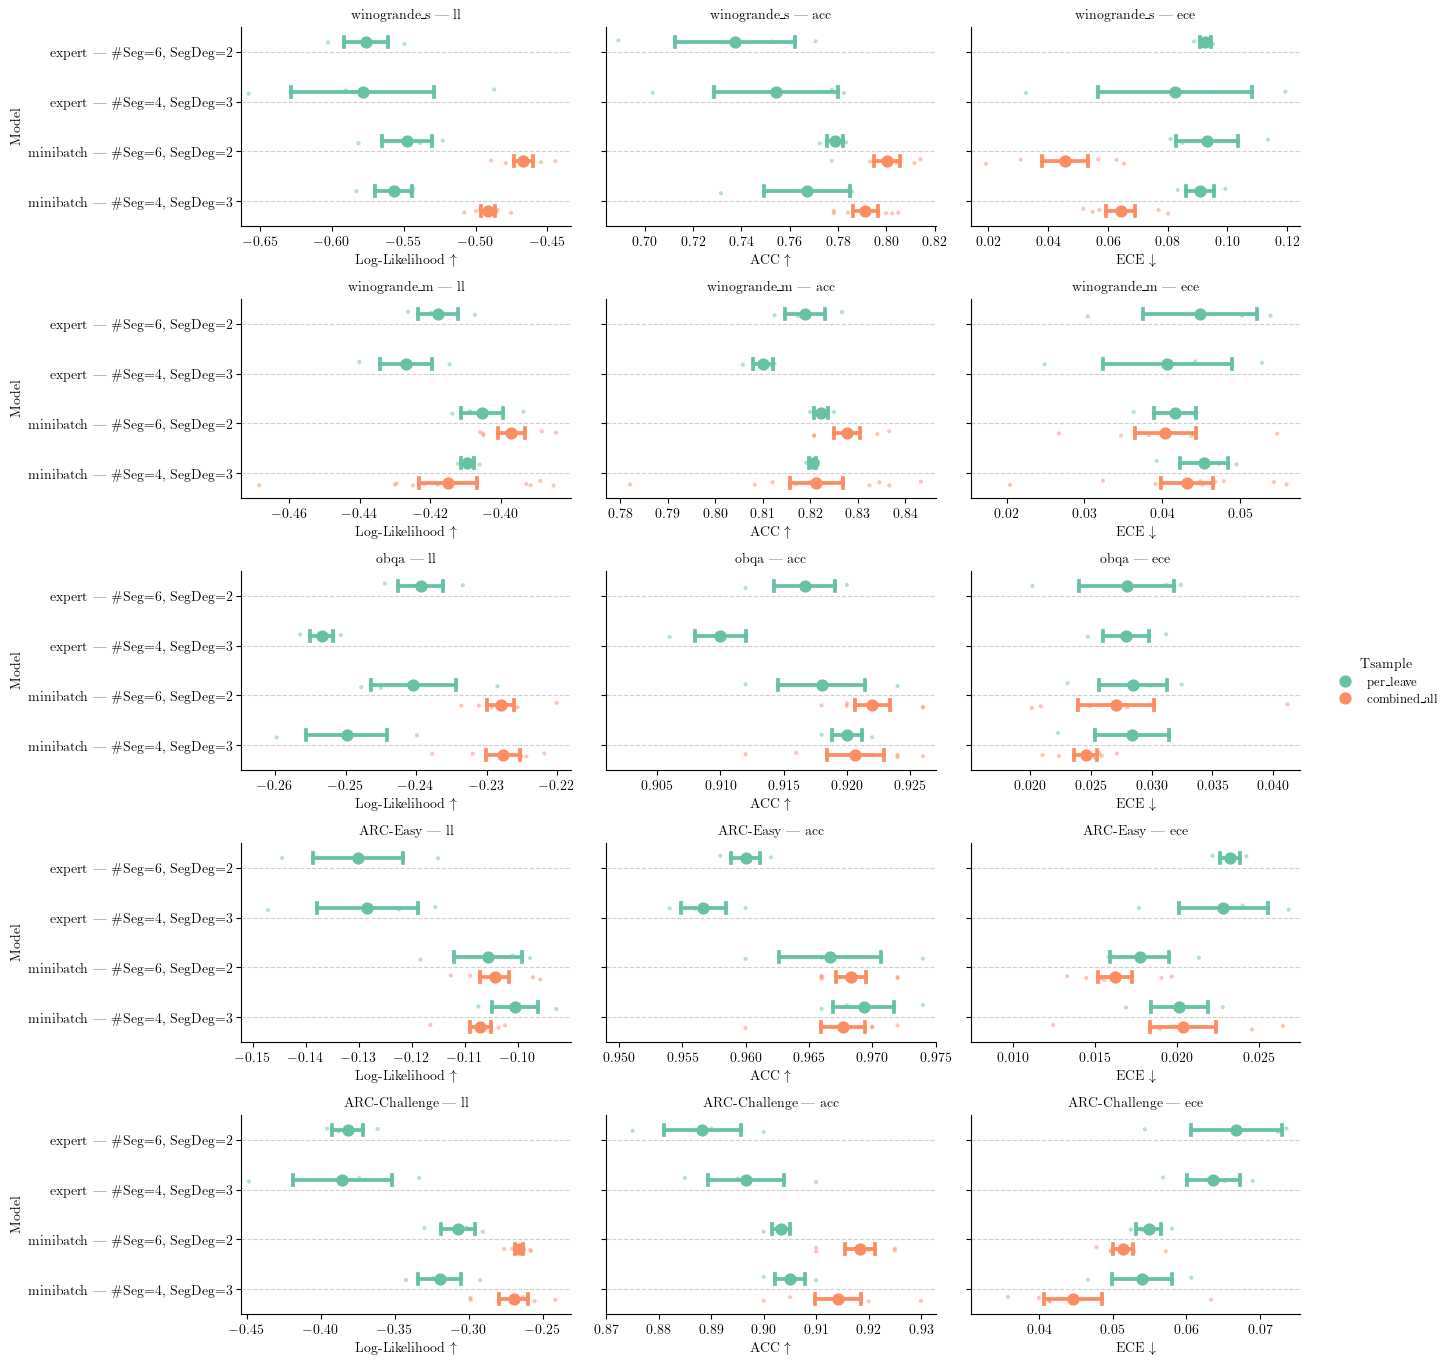

In [141]:
# stack df_vi to df_plot
df_plot_ = pd.concat([df_plot,], ignore_index=True)
# remove duplicates
df_plot_ = df_plot_.groupby(variable_idx+['Model', 'Seed', 'Metric'])['value'].mean().reset_index()

# hue
hue_name = 'Tsample'
hue_order = df_plot_[hue_name].unique()
hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))
col_order = "ll", "acc", "ece"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge",
order = df_plot_['Model'].unique()

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Dataset', col='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.4, sharex=False, height=figsize[0]/2, aspect=1.618,
    legend=True, errorbar="se", ) # hue_order=hue_order,)

# Overlay strip plots for original points (small, alpha=0.5)
for (ds, metric), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=0.4, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/performance_pointplot.png", dpi=300)
# plt.savefig("result/performance_pointplot.pdf", dpi=300)
plt.show()

In [142]:
# filter out only similar seed runs
df_plot_.groupby(variable_idx)['Seed'].unique()

Dataset        BmaMode      DS_Sampling  DS_Mode  DS_WindowSize  Tsample       CurveSegmentDegree  NCurveSegment
ARC-Challenge  PPD Uniform  expert       Random    4             per_leave     2                   6                                                       [1, 2, 20]
                                                                               3                   4                                                       [1, 2, 20]
                            minibatch    classic  -1             combined_all  2                   6                                [2, 40, 800, 16000, 32000, 64000]
                                                                               3                   4                                [2, 40, 800, 16000, 32000, 64000]
                                                                 per_leave     2                   6                                                       [1, 2, 20]
                                                         

Models set() missing:


/tmp/ipykernel_888869/2605597187.py:17: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


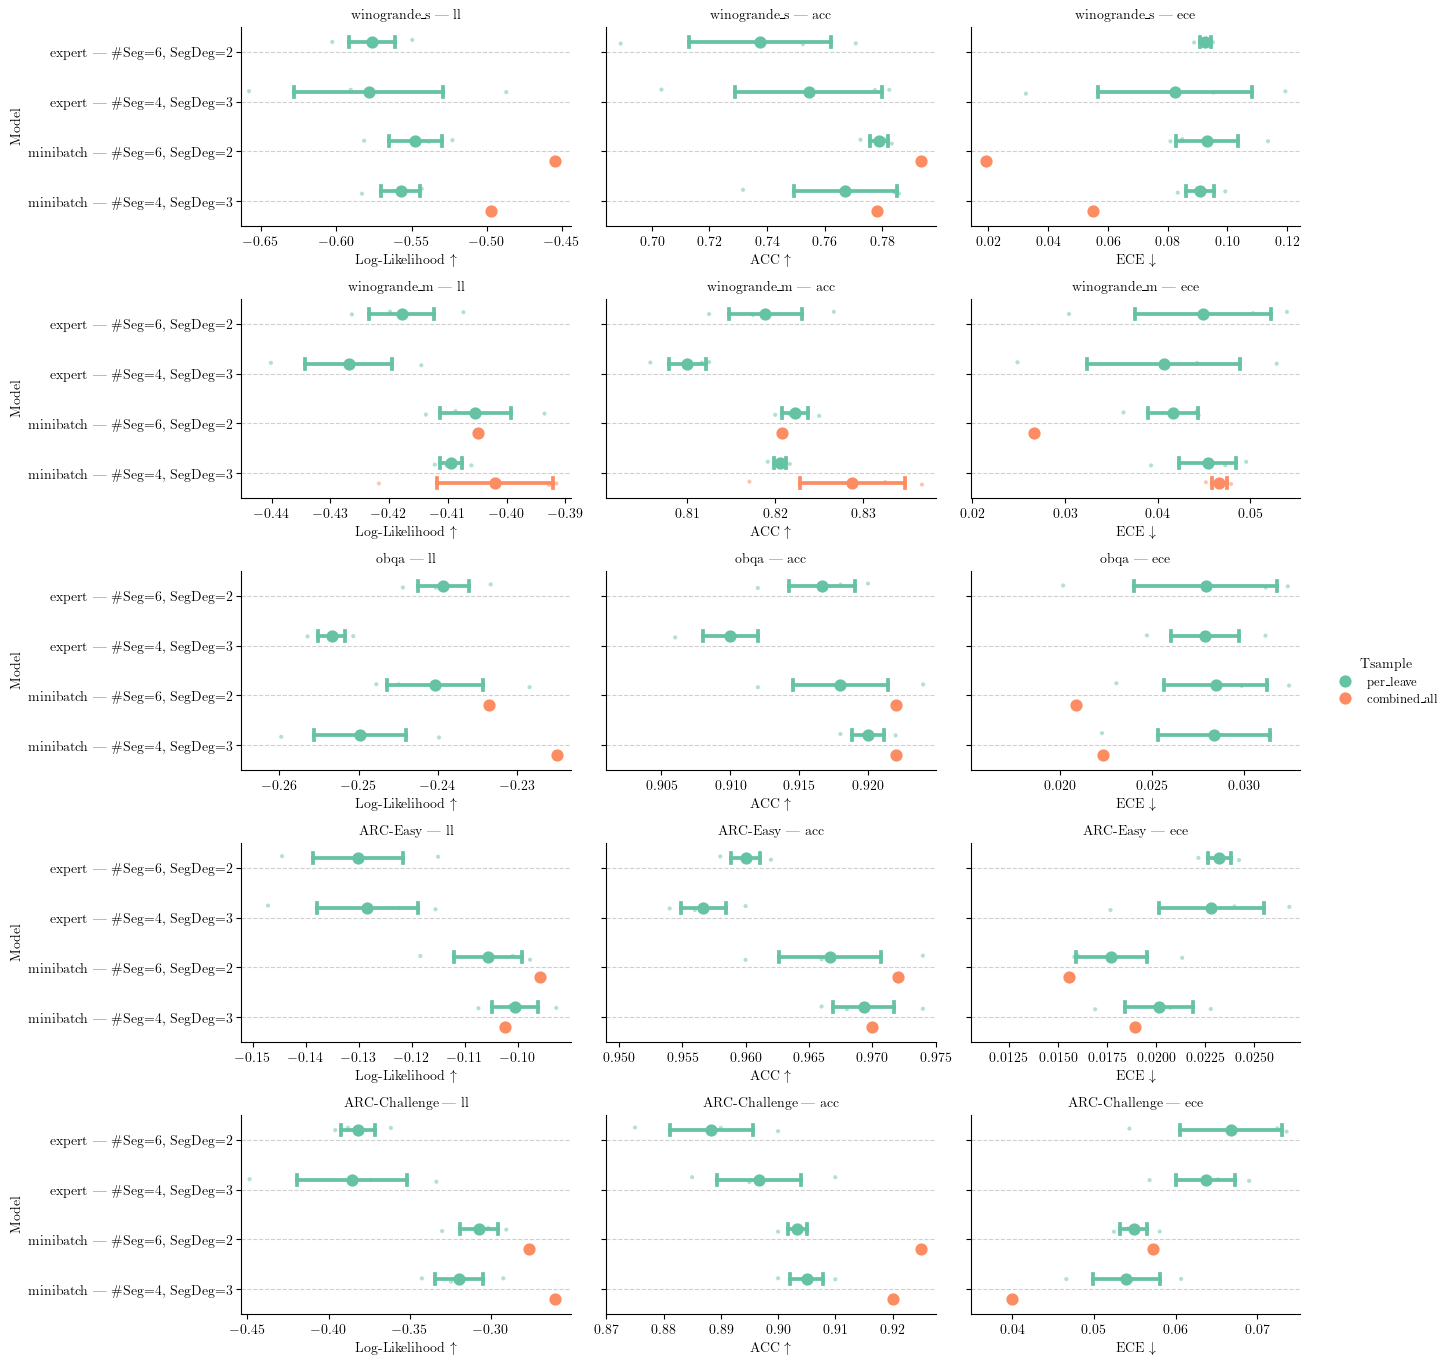

In [146]:
# stack df_vi to df_plot
df_plot_ = pd.concat([df_plot,], ignore_index=True)
df_plot_ = df_plot_.groupby(variable_idx+['Model', 'Seed', 'Metric'])['value'].mean().reset_index()
df_plot_ = df_plot_[df_plot_['Seed'].isin([1,2,20])]


# hue
hue_name = 'Tsample'
hue_order = df_plot_[hue_name].unique()
hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))
col_order = "ll", "acc", "ece"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge",
order = df_plot_['Model'].unique()

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Dataset', col='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.4, sharex=False, height=figsize[0]/2, aspect=1.618,
    legend=True, errorbar="se", ) # hue_order=hue_order,)

# Overlay strip plots for original points (small, alpha=0.5)
for (ds, metric), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=0.4, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/performance_pointplot.png", dpi=300)
# plt.savefig("result/performance_pointplot.pdf", dpi=300)
plt.show()

In [144]:
df_plot_.groupby(variable_idx+['Seed', 'Metric'])['value'].count().unique()

array([1])